# Elastic Deformation of Two-Dimensional Objects — NLAnew

**NLA group project.** Triangular meshes of a 2D elastic sheet produce a sparse, symmetric
positive-definite (SPD) stiffness system $K\,d = f$. We study how **geometry, loads and supports**
affect the deformation and the behaviour of numerical solvers.

This notebook is the restructured version of `NLA-p2`. The mathematics is unchanged; the code is
split so that **each cell has one purpose and produces one output** (a number, a table or a figure)
that can be pasted back to verify correctness.

**Structure**

- **Part 1 — Meshes.** Mesh families, shape catalogue, one `MeshSuite` export.
- **Part 2 — Elasticity assembly.** The real 2D elasticity matrix $K$
  ($2n_v\times 2n_v$). **This is the one matrix used by every analysis below.**
- **Part 3 — Analysis on $K$.** Sizing, sparsity/bandwidth, conditioning $\kappa$, CG iterations and
  the effect of mesh quality — all measured on elasticity $K$, not a placeholder.
- **Part 4 — Verification.** Elasticity patch test and compliance convergence, plus a *solved*
  scalar-Poisson $L^2/H^1$ convergence check that proves the FE machinery converges at the right rate.
- **Part 5 — Physics.** Two support cases under gravity: whole-boundary-clamped vs.
  bottom-edge-clamped; deformation and stress fields.

Every "random" mesh uses a fixed seed, so results are reproducible.

---
# Part 1 — Meshes 

Sections 1–9 are the mesh generator, the shape catalogue, the validation suite and the `MeshSuite`
export. They are the input to everything that follows.

## 1. Setup

**Objective.** Fix every shared constant (seed, material) and record library versions so the whole
pipeline is reproducible. **Output.** Versions and the frozen constants.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.spatial import Delaunay
import time

# Reproducibility: every "random" mesh (distorted, unstructured) uses this seed.
SEED = 0

# Material constants 
E_MOD = 1.0
NU    = 0.3

print(f"numpy      {np.__version__}")
print(f"scipy      {__import__('scipy').__version__}")
print(f"matplotlib {plt.matplotlib.__version__}")
print(f"pandas     {pd.__version__}")
print(f"SEED = {SEED},  E = {E_MOD},  nu = {NU}")

numpy      2.1.3
scipy      1.16.0
matplotlib 3.10.0
pandas     2.2.3
SEED = 0,  E = 1.0,  nu = 0.3


## 2. Structured mesh

**Objective.** The reference grid: $[0,1]^2$ split into $n\times n$ squares, each cut along the
$(a,c)$ diagonal into triangles $(a,b,c)$ and $(a,c,d)$. Gives $(n+1)^2$ nodes, $2n^2$ triangles,
$h=1/n$. The distorted and unstructured families derive from it.

**Output.** Node/triangle counts for $n=1,2,4,8$ vs. expected.

In [3]:
def structured_mesh(n):
    """Unit square split into n x n squares, each cut along the (a,c) diagonal.
    Returns nodes (n_v,2) float64 and elements (n_t,3) int, CCW by construction."""
    xs = np.linspace(0, 1, n + 1)
    X, Y = np.meshgrid(xs, xs)
    nodes = np.column_stack([X.ravel(), Y.ravel()])
    idx = np.arange((n + 1) ** 2).reshape(n + 1, n + 1)  # idx[j, i] = node at (x_i, y_j)
    a = idx[:-1, :-1].ravel()   # lower-left
    b = idx[:-1, 1:].ravel()    # lower-right
    c = idx[1:, 1:].ravel()     # upper-right
    d = idx[1:, :-1].ravel()    # upper-left
    elements = np.vstack([np.column_stack([a, b, c]),
                          np.column_stack([a, c, d])])
    return nodes, elements

for n in [1, 2, 4, 8]:
    v, e = structured_mesh(n)
    print(f"n={n}:  n_v={len(v):3d}   n_t={len(e):3d}   (expected {(n+1)**2}, {2*n*n})")

n=1:  n_v=  4   n_t=  2   (expected 4, 2)
n=2:  n_v=  9   n_t=  8   (expected 9, 8)
n=4:  n_v= 25   n_t= 32   (expected 25, 32)
n=8:  n_v= 81   n_t=128   (expected 81, 128)


## 3. Mesh helpers

**Objective.** Four utilities used throughout:

| function | role |
|---|---|
| `triangle_areas` | signed area (positive = CCW) |
| `make_ccw` | flip corners of negatively-oriented triangles |
| `boundary_nodes_of` | nodes on edges in exactly one triangle |
| `remove_region` | cut a hole and renumber survivors |

`boundary_nodes_of` uses the rule: a boundary edge appears in one triangle, an interior edge in two.
These are the nodes the Dirichlet condition acts on.

**Output.** A micro-test on $n=2$ and on a single-square cut-out.

In [4]:
def triangle_areas(nodes, elements):
    """Signed area (positive if vertices are counter-clockwise)."""
    P = nodes[elements]
    return 0.5 * ((P[:, 1, 0] - P[:, 0, 0]) * (P[:, 2, 1] - P[:, 0, 1])
                - (P[:, 2, 0] - P[:, 0, 0]) * (P[:, 1, 1] - P[:, 0, 1]))

def make_ccw(nodes, elements):
    """Reorder corners of negatively-oriented triangles so every area > 0."""
    el = elements.copy()
    neg = triangle_areas(nodes, el) < 0
    el[neg] = el[neg][:, [0, 2, 1]]
    return el

def boundary_nodes_of(elements):
    """Nodes on edges shared by exactly one triangle."""
    e = np.vstack([elements[:, [0, 1]], elements[:, [1, 2]], elements[:, [2, 0]]])
    e = np.sort(e, axis=1)
    uniq, counts = np.unique(e, axis=0, return_counts=True)
    return np.unique(uniq[counts == 1])

def remove_region(nodes, elements, is_removed):
    """Delete triangles whose centroid satisfies is_removed(x,y); renumber survivors 0..n_v-1."""
    c = nodes[elements].mean(axis=1)
    elements = elements[~is_removed(c[:, 0], c[:, 1])]
    used = np.unique(elements)
    remap = -np.ones(len(nodes), dtype=int)
    remap[used] = np.arange(len(used))
    return nodes[used], remap[elements]

v, e = structured_mesh(2)
areas = triangle_areas(v, e)
print(f"triangle areas : min={areas.min():.4f}  max={areas.max():.4f}  all>0? {bool((areas>0).all())}")
print(f"sum of areas   : {areas.sum():.4f}   (expected 1.0000)")
print(f"boundary nodes : {len(boundary_nodes_of(e))}   (expected 8, the perimeter)")
v2, e2 = remove_region(v, e, lambda x, y: (x > 0.5) & (y > 0.5))
print(f"after cutting top-right square: n_v={len(v2)}  n_t={len(e2)}  sum_area={triangle_areas(v2,e2).sum():.4f}")

triangle areas : min=0.1250  max=0.1250  all>0? True
sum of areas   : 1.0000   (expected 1.0000)
boundary nodes : 8   (expected 8, the perimeter)
after cutting top-right square: n_v=8  n_t=6  sum_area=0.7500


## 4. Mesh generator

**Objective.** One function, three kinds:

| kind | how it is built | what it tests |
|---|---|---|
| `structured` | reference grid | baseline |
| `distorted` | same connectivity, interior nodes jittered | mesh quality at fixed $h$ |
| `unstructured` | jittered nodes, then Delaunay | topology variation |

`boundary_nodes_of` is computed **before** jittering, so the outer/hole borders never move. The
generator asserts no triangle folds. Default jitter: $0.30\,h$ (unstructured), $0.25\,h$ (distorted).

**Output.** One call per kind at $n=8$ with min/total area.

In [5]:
def generate_mesh(kind, level, remove=None, jitter=None, seed=SEED):
    """Build a mesh of the unit square.
    kind  : 'structured' | 'unstructured' | 'distorted'
    level : n (squares per side, h = 1/n)
    remove: callable (x, y) -> bool, True where triangles are cut out
    Returns nodes, elements (CCW), boundary_nodes."""
    n = level
    h = 1.0 / n
    if jitter is None:
        jitter = 0.3 if kind == 'unstructured' else 0.25
    nodes, elements = structured_mesh(n)
    if remove is not None:
        nodes, elements = remove_region(nodes, elements, remove)
    if kind in ('distorted', 'unstructured'):
        keep_fixed = boundary_nodes_of(elements)
        move = np.ones(len(nodes), bool)
        move[keep_fixed] = False
        rng = np.random.default_rng(seed)
        nodes = nodes.copy()
        nodes[move] += rng.uniform(-jitter * h, jitter * h, (move.sum(), 2))
        if kind == 'unstructured':
            elements = Delaunay(nodes).simplices
            elements = make_ccw(nodes, elements)
            if remove is not None:                 # Delaunay re-fills the holes
                nodes, elements = remove_region(nodes, elements, remove)
    elif kind != 'structured':
        raise ValueError(f"unknown kind '{kind}'")
    amin = triangle_areas(nodes, elements).min()
    assert amin > 1e-12 * h ** 2, \
        f"folded or degenerate mesh (min signed area {amin:.2e}): reduce jitter"
    return nodes, elements, boundary_nodes_of(elements)

for kind in ['structured', 'distorted', 'unstructured']:
    v, e, b = generate_mesh(kind, 8)
    a = triangle_areas(v, e)
    print(f"{kind:12s}: n_v={len(v):4d}  n_t={len(e):4d}  n_bnd={len(b):3d}  "
          f"min_area={a.min():.2e}  total_area={a.sum():.4f}")

structured  : n_v=  81  n_t= 128  n_bnd= 32  min_area=7.81e-03  total_area=1.0000
distorted   : n_v=  81  n_t= 128  n_bnd= 32  min_area=3.47e-03  total_area=1.0000
unstructured: n_v=  81  n_t= 128  n_bnd= 32  min_area=2.79e-03  total_area=1.0000


## 5. Shape catalogue

**Objective.** Ten shapes, one per geometric scenario, each `(remove_function, n_holes, exact_area)`.
Edges of the nine exact shapes lie on multiples of $1/8$, so the mesh is exact when `level` is a
multiple of 8. `disk` is curved (area approximate, 1% tolerance). **Output.** The catalogue table.

In [6]:
SHAPES = {
    'square':    (None, 0, 1.0),
    'hole':      (lambda x, y: (x > 3/8) & (x < 5/8) & (y > 3/8) & (y < 5/8), 1, 1 - 1/16),
    'hole_off':  (lambda x, y: (x > 1/8) & (x < 3/8) & (y > 1/8) & (y < 3/8), 1, 1 - 1/16),
    'two_holes': (lambda x, y: ((x > 1/8) & (x < 3/8) & (y > 1/8) & (y < 3/8)) |
                               ((x > 5/8) & (x < 7/8) & (y > 5/8) & (y < 7/8)), 2, 1 - 2/16),
    'frame':     (lambda x, y: (x > 1/4) & (x < 3/4) & (y > 1/4) & (y < 3/4), 1, 1 - 1/4),
    'L':         (lambda x, y: (x > 1/2) & (y > 1/2), 0, 3/4),
    'U':         (lambda x, y: (x > 3/8) & (x < 5/8) & (y > 3/8), 0, 1 - 5/32),
    'T':         (lambda x, y: ((x < 3/8) | (x > 5/8)) & (y < 5/8), 0, 1 - 15/32),
    'cross':     (lambda x, y: ((x < 1/4) | (x > 3/4)) & ((y < 1/4) | (y > 3/4)), 0, 3/4),
}
SHAPES_APPROX = {
    'disk':      (lambda x, y: (x - .5) ** 2 + (y - .5) ** 2 < 0.2 ** 2, 1, 1 - np.pi * 0.2 ** 2),
}

rows = []
for name, (_, holes, area) in {**SHAPES, **SHAPES_APPROX}.items():
    rows.append({'shape': name, 'holes': holes, 'exact_area': area, 'approx?': name in SHAPES_APPROX})
print(pd.DataFrame(rows).to_string(index=False))

    shape  holes  exact_area  approx?
   square      0    1.000000    False
     hole      1    0.937500    False
 hole_off      1    0.937500    False
two_holes      2    0.875000    False
    frame      1    0.750000    False
        L      0    0.750000    False
        U      0    0.843750    False
        T      0    0.531250    False
    cross      0    0.750000    False
     disk      1    0.874336     True


## 6. Validation

**Objective.** Three invariants per mesh: (1) Euler $V-E+F = 1-n_{\text{holes}}$, (2) no orphan
nodes, (3) total area matches the exact domain. **Output.** A smoke test (`hole`, structured, 16).

In [7]:
def get_mesh(shape, kind, level, **kw):
    """Convenience wrapper: catalogue shape -> (nodes, elements, boundary_nodes)."""
    table = {**SHAPES, **SHAPES_APPROX}
    if shape not in table:
        raise ValueError(f"unknown shape '{shape}'. Options: {list(table)}")
    remove = table[shape][0]
    if remove is not None and shape in SHAPES:
        assert level % 8 == 0, f"shape '{shape}' needs level divisible by 8"
    return generate_mesh(kind, level, remove=remove, **kw)

def validate_mesh(nodes, elements, n_holes=0, expected_area=None, tol=1e-10, verbose=True):
    """Euler check, orphan-node check, area check."""
    e = np.sort(np.vstack([elements[:, [0, 1]], elements[:, [1, 2]], elements[:, [2, 0]]]), axis=1)
    n_e = len(np.unique(e, axis=0))
    euler = len(nodes) - n_e + len(elements)
    area = triangle_areas(nodes, elements).sum()
    if verbose:
        print(f"nodes {len(nodes)}, triangles {len(elements)}, edges {n_e}, "
              f"Euler {euler} (expected {1 - n_holes}), area {area:.4f}")
    assert euler == 1 - n_holes, "invalid mesh: wrong Euler number"
    assert len(np.unique(elements)) == len(nodes), "orphan node"
    if expected_area is not None:
        assert abs(area - expected_area) < tol, f"area {area:.6f} != expected {expected_area:.6f}"
    return True

def check_shape(shape, kind, level):
    """Build a catalogue mesh and validate it against its known holes / area."""
    table = {**SHAPES, **SHAPES_APPROX}
    _, n_holes, area = table[shape]
    nodes, elements, _ = get_mesh(shape, kind, level)
    tol = 1e-10 if shape in SHAPES else 0.01
    validate_mesh(nodes, elements, n_holes, area, tol, verbose=False)
    return len(nodes), len(elements)

print("hole, structured, level=16:")
check_shape('hole', 'structured', 16)
v, e, b = get_mesh('hole', 'structured', 16)
print("validate_mesh ->", validate_mesh(v, e, n_holes=1, expected_area=15/16))

hole, structured, level=16:
nodes 280, triangles 480, edges 760, Euler 0 (expected 0), area 0.9375
validate_mesh -> True


## 7. Verification suite

**Objective.** (a) Structured scaling at $n=1..32$ (counts + Euler), (b) full shape × kind × level
matrix (must be a complete pass). **Output.** The scaling table and the failure count.

In [8]:
rows = []
for n in [1, 2, 4, 8, 16, 32]:
    v, e, _ = generate_mesh('structured', n)
    a = triangle_areas(v, e)
    edges = np.unique(np.sort(np.vstack([e[:, [0, 1]], e[:, [1, 2]], e[:, [2, 0]]]), axis=1), axis=0)
    rows.append({'n': n, 'h': 1 / n, 'n_v': len(v), 'n_t': len(e),
                 'expected_n_v': (n + 1) ** 2, 'expected_n_t': 2 * n * n,
                 'Euler': len(v) - len(edges) + len(e),
                 'total_area': a.sum(), 'min_area': a.min()})
print(pd.DataFrame(rows).to_string(index=False, float_format='%.4e'))

 n          h  n_v  n_t  expected_n_v  expected_n_t  Euler  total_area   min_area
 1 1.0000e+00    4    2             4             2      1  1.0000e+00 5.0000e-01
 2 5.0000e-01    9    8             9             8      1  1.0000e+00 1.2500e-01
 4 2.5000e-01   25   32            25            32      1  1.0000e+00 3.1250e-02
 8 1.2500e-01   81  128            81           128      1  1.0000e+00 7.8125e-03
16 6.2500e-02  289  512           289           512      1  1.0000e+00 1.9531e-03
32 3.1250e-02 1089 2048          1089          2048      1  1.0000e+00 4.8828e-04


In [9]:
results = []
for shape in list(SHAPES) + list(SHAPES_APPROX):
    levels = [8, 16, 32, 64] if shape in SHAPES else [16, 32, 64]
    for kind in ['structured', 'distorted', 'unstructured']:
        for level in levels:
            try:
                check_shape(shape, kind, level)
                results.append({'shape': shape, 'kind': kind, 'level': level, 'status': 'OK'})
            except AssertionError as ex:
                results.append({'shape': shape, 'kind': kind, 'level': level, 'status': f'FAIL: {ex}'})
df = pd.DataFrame(results)
n_fail = (df['status'] != 'OK').sum()
print(f"TOTAL: {len(df)} tests, {n_fail} failures")
print("FAILURES:", "none" if not n_fail else df[df['status'] != 'OK'].to_string(index=False))

TOTAL: 117 tests, 0 failures
FAILURES: none


## 8. Visualization

**Objective.** Figure A — the three mesh kinds at $n=16$. Figure B — every catalogue shape at
$n=16$ with boundary nodes marked. **Output.** Two figures.

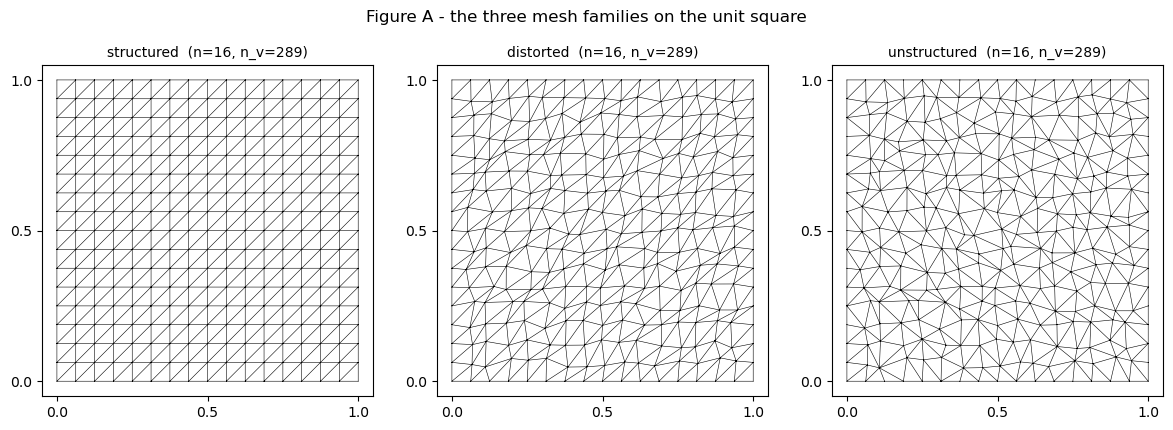

In [10]:
def plot_mesh(ax, nodes, elements, title):
    ax.triplot(nodes[:, 0], nodes[:, 1], elements, lw=0.4, color='k')
    ax.set_aspect('equal'); ax.set_title(title, fontsize=10)
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, kind in zip(axes, ['structured', 'distorted', 'unstructured']):
    v, e, _ = generate_mesh(kind, 16)
    plot_mesh(ax, v, e, f"{kind}  (n=16, n_v={len(v)})")
plt.suptitle("Figure A - the three mesh families on the unit square", y=1.02)
plt.tight_layout(); plt.show()

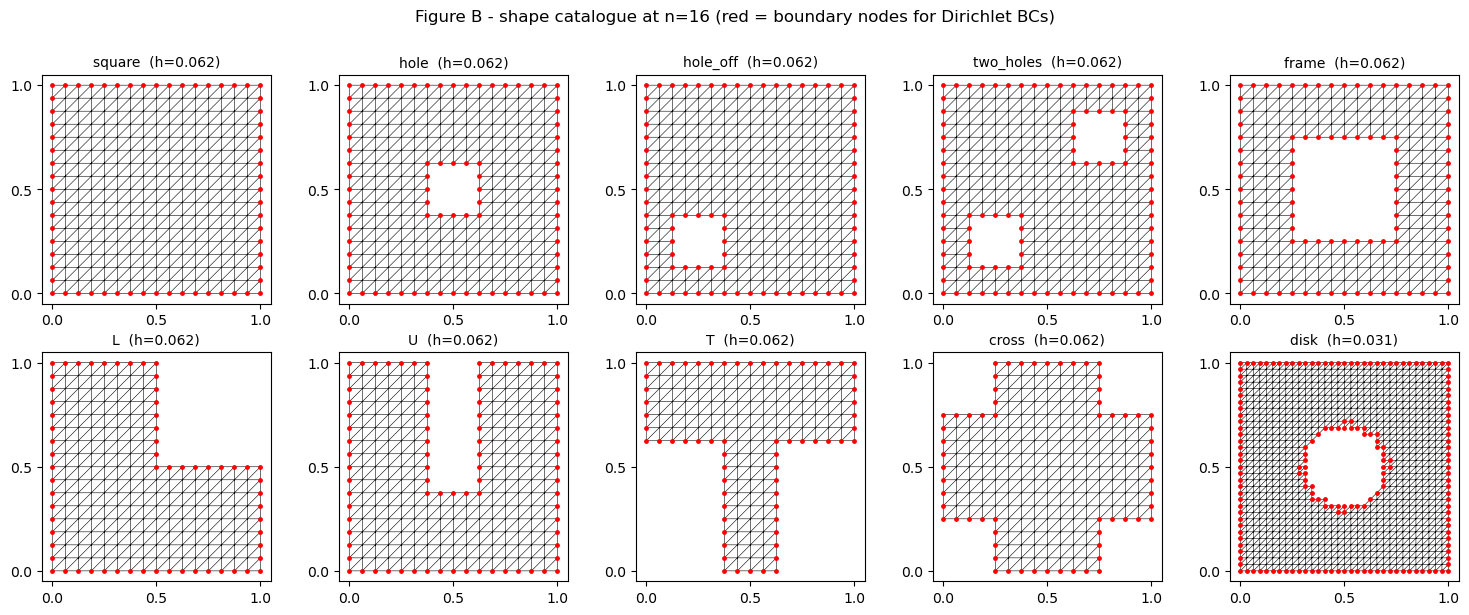

In [11]:
all_shapes = list(SHAPES) + list(SHAPES_APPROX)
ncol = 5
nrow = int(np.ceil(len(all_shapes) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3 * ncol, 3 * nrow))
axes = axes.ravel()
for ax, shape in zip(axes, all_shapes):
    level = 16 if shape in SHAPES else 32
    v, e, b = get_mesh(shape, 'structured', level)
    plot_mesh(ax, v, e, f"{shape}  (h={1/level:.3f})")
    ax.scatter(v[b, 0], v[b, 1], s=6, c='r', zorder=3)
for ax in axes[len(all_shapes):]:
    ax.axis('off')
plt.suptitle("Figure B - shape catalogue at n=16 (red = boundary nodes for Dirichlet BCs)", y=1.01)
plt.tight_layout(); plt.show()

## 9. Export — the `MeshSuite` object

**Objective.** Hand the rest of the notebook one consistent object per mesh, so Part 2 (assembly)
and Part 3 (analysis) never touch `SHAPES`, jitter or seeding directly. `build_suite_all` produces
the frozen experiment matrix: `square + hole + L + U` × 3 kinds × 3 levels.

**Output.** A summary table of all suites and the total DOF count.

In [12]:
MATERIAL = {'E': E_MOD, 'nu': NU}

# The experiment matrix frozen by the team (shape, kind, level).
EXPERIMENT_MATRIX = [
    (shape, kind, level)
    for shape in ['square', 'hole', 'L', 'U']
    for kind  in ['structured', 'distorted', 'unstructured']
    for level in [8, 16, 32]
]

def build_suite(shape, kind, level):
    """Wrap one mesh as a MeshSuite dict ready for the elasticity assembly."""
    v, e, b = get_mesh(shape, kind, level)
    table = {**SHAPES, **SHAPES_APPROX}
    return {
        'shape': shape, 'kind': kind, 'level': level, 'h': 1.0 / level,
        'n_holes': table[shape][1],
        'nodes': v, 'elements': e, 'boundary_nodes': b,
        'n_dof': 2 * len(v),
        **MATERIAL,
    }

def build_suite_all():
    """Return the full experiment matrix as a list of MeshSuite dicts."""
    return [build_suite(s, k, l) for s, k, l in EXPERIMENT_MATRIX]

suites = build_suite_all()
rows = [{'shape': s['shape'], 'kind': s['kind'], 'level': s['level'],
         'n_v': len(s['nodes']), 'n_t': len(s['elements']),
         'n_bnd': len(s['boundary_nodes']), 'n_dof': s['n_dof']}
        for s in suites]
print(pd.DataFrame(rows).to_string(index=False))
print(f"\n{len(suites)} suites produced, "
      f"{sum(s['n_dof'] for s in suites)} total DOFs across the experiment matrix")

 shape         kind  level  n_v  n_t  n_bnd  n_dof
square   structured      8   81  128     32    162
square   structured     16  289  512     64    578
square   structured     32 1089 2048    128   2178
square    distorted      8   81  128     32    162
square    distorted     16  289  512     64    578
square    distorted     32 1089 2048    128   2178
square unstructured      8   81  128     32    162
square unstructured     16  289  512     64    578
square unstructured     32 1089 2048    128   2178
  hole   structured      8   80  120     40    160
  hole   structured     16  280  480     80    560
  hole   structured     32 1040 1920    160   2080
  hole    distorted      8   80  120     40    160
  hole    distorted     16  280  480     80    560
  hole    distorted     32 1040 1920    160   2080
  hole unstructured      8   80  120     40    160
  hole unstructured     16  280  480     80    560
  hole unstructured     32 1040 1920    160   2080
     L   structured      8   65

---
# Part 2 — Elasticity assembly 

This part builds the **real 2D linear-elasticity stiffness matrix** $K$. Every analysis in Parts 3–5
uses this $K$.

**Convention.** Each node $i$ has two DOFs: global DOF $2i=u_x$, $2i{+}1=u_y$. The global system is
$K\,d=f$ with $d\in\mathbb{R}^{2n_v}$. After removing fixed DOFs the reduced system is
$K_{ff}\,d_f=f_f$.

## 10. Shared geometry + strain–displacement $B$

**Objective.** Define the per-triangle geometry once.

For a P1 triangle with vertices $(x_i,y_i)$:
$$b_i = y_j - y_k,\quad c_i = x_k - x_j \quad (i,j,k\ \text{cyclic}),\qquad A=\tfrac12\,[(x_1-x_0)(y_2-y_0)-(x_2-x_0)(y_1-y_0)].$$
The strain–displacement matrix is constant per element:
$$B=\frac{1}{2A}\begin{bmatrix} b_0&0&b_1&0&b_2&0\\ 0&c_0&0&c_1&0&c_2\\ c_0&b_0&c_1&b_1&c_2&b_2\end{bmatrix}.$$

**Output.** `B` for the single reference triangle of `structured_mesh(1)`, and a check that the
columns of $B$ sum to zero (rigid-body translation produces no strain).

In [13]:
def tri_geometry(nodes, elements):
    """Per-triangle geometry shared by every assembly routine.
    Returns P (n_t,3,2) vertex coords, b (n_t,3), c (n_t,3), A (n_t,) signed area."""
    P = nodes[elements]
    x, y = P[:, :, 0], P[:, :, 1]
    b = np.column_stack([y[:, 1] - y[:, 2], y[:, 2] - y[:, 0], y[:, 0] - y[:, 1]])  # b_i = y_j - y_k
    c = np.column_stack([x[:, 2] - x[:, 1], x[:, 0] - x[:, 2], x[:, 1] - x[:, 0]])  # c_i = x_k - x_j
    A = 0.5 * ((x[:, 1] - x[:, 0]) * (y[:, 2] - y[:, 0])
             - (x[:, 2] - x[:, 0]) * (y[:, 1] - y[:, 0]))
    return P, b, c, A

def strain_displacement_B(b, c, A):
    """Vectorised (n_t, 3, 6) strain-displacement matrix B for all triangles at once."""
    nt = b.shape[0]
    B = np.zeros((nt, 3, 6))
    inv2A = 1.0 / (2.0 * A)
    for i in range(3):
        B[:, 0, 2*i]     = b[:, i] * inv2A
        B[:, 1, 2*i + 1] = c[:, i] * inv2A
        B[:, 2, 2*i]     = c[:, i] * inv2A
        B[:, 2, 2*i + 1] = b[:, i] * inv2A
    return B

_v, _e = structured_mesh(1)
_P, _b, _c, _A = tri_geometry(_v, _e)
_B = strain_displacement_B(_b, _c, _A)
print("reference triangle 0, B =\n", np.round(_B[0], 4))
# Rigid translation u=(1,0) -> strain must be 0: sum of the u_x columns of B is zero.
ux_cols = _B[0][:, 0::2].sum(axis=1)
print("sum of u_x columns of B (expect ~0):", np.round(ux_cols, 12))

reference triangle 0, B =
 [[-1.  0.  1.  0.  0.  0.]
 [ 0.  0.  0. -1.  0.  1.]
 [ 0. -1. -1.  1.  1.  0.]]
sum of u_x columns of B (expect ~0): [0. 0. 0.]


## 11. Material model $D$

**Objective.** The $3\times3$ constitutive matrix relating stress $\sigma=D\varepsilon$ in Voigt
notation $\sigma=[\sigma_{xx},\sigma_{yy},\tau_{xy}]$, $\varepsilon=[\varepsilon_{xx},\varepsilon_{yy},\gamma_{xy}]$,
for plane strain or plane stress. **Output.** Both matrices for $E=1,\ \nu=0.3$.

In [14]:
def material_matrix(E, nu, model='plane_strain'):
    """3x3 constitutive matrix D for isotropic linear elasticity."""
    if model == 'plane_strain':
        c = E / ((1 + nu) * (1 - 2 * nu))
        D = c * np.array([[1 - nu, nu,     0],
                          [nu,     1 - nu, 0],
                          [0,      0,      (1 - 2*nu) / 2]])
    elif model == 'plane_stress':
        c = E / (1 - nu**2)
        D = c * np.array([[1,  nu, 0],
                          [nu, 1,  0],
                          [0,  0,  (1 - nu) / 2]])
    else:
        raise ValueError(f"unknown model '{model}' (use 'plane_strain' or 'plane_stress')")
    return D

print("plane_strain D =\n", np.round(material_matrix(1.0, 0.3, 'plane_strain'), 4))
print("\nplane_stress D =\n", np.round(material_matrix(1.0, 0.3, 'plane_stress'), 4))

plane_strain D =
 [[1.3462 0.5769 0.    ]
 [0.5769 1.3462 0.    ]
 [0.     0.     0.3846]]

plane_stress D =
 [[1.0989 0.3297 0.    ]
 [0.3297 1.0989 0.    ]
 [0.     0.     0.3846]]


## 12. Element stiffness and global assembly

**Objective.** Build all element matrices $K_e=A_e\,B^\top D\,B$ (6×6) at once, then scatter them
into the global sparse $K$ of size $2n_v\times 2n_v$ with the interleaved DOF map
$node\ j\to[2j,\,2j{+}1]$. Uses the shared `tri_geometry` / `strain_displacement_B`.

**Output.** $K$ for `square`, structured, $n=8$: shape, nnz, and symmetry $\|K-K^\top\|/\|K\|$.

In [15]:
def element_stiffness(nodes, elements, D):
    """All element stiffness matrices K_e = A_e B^T D B, shape (n_t, 6, 6)."""
    _, b, c, A = tri_geometry(nodes, elements)
    B = strain_displacement_B(b, c, A)
    BtD = np.einsum('eji,jk->eik', B, D)          # (n_t, 6, 3)
    Ke  = np.einsum('e,eij,ejk->eik', A, BtD, B)  # (n_t, 6, 6)
    return Ke

def assemble_stiffness_elasticity(nodes, elements, D):
    """Assemble the global 2n_v x 2n_v stiffness matrix K (CSR)."""
    Ke = element_stiffness(nodes, elements, D)
    nt, nv = len(elements), len(nodes)
    dof = np.empty((nt, 6), dtype=int)            # interleaved [2n0,2n0+1,2n1,...]
    for i in range(3):
        dof[:, 2*i]     = 2 * elements[:, i]
        dof[:, 2*i + 1] = 2 * elements[:, i] + 1
    I = np.broadcast_to(dof[:, :, None], Ke.shape).ravel()
    J = np.broadcast_to(dof[:, None, :], Ke.shape).ravel()
    return sp.coo_matrix((Ke.ravel(), (I, J)), shape=(2*nv, 2*nv)).tocsr()

D = material_matrix(E_MOD, NU, 'plane_strain')
v, e, b = generate_mesh('structured', 8)
K = assemble_stiffness_elasticity(v, e, D)
rel_sym = spla.norm(K - K.T) / spla.norm(K)
print(f"K: shape={K.shape}, nnz={K.nnz}")
print(f"symmetry ||K - K^T|| / ||K|| = {rel_sym:.2e}  (expect ~1e-16)")

K: shape=(162, 162), nnz=1988
symmetry ||K - K^T|| / ||K|| = 0.00e+00  (expect ~1e-16)


## 13. Load vector (body force) and gravity

**Objective.** Consistent P1 load for a body force $f(x,y)=(f_x,f_y)$: each node of a triangle
receives $A/3$ of the centroid value (1-point rule, exact for constant $f$). `gravity_load` returns
the downward body force used in Part 5. **Output.** The total vertical load for `square`, $n=8$
(should equal $-\rho g \cdot \text{area}=-9.81$).

In [16]:
def assemble_load_vector(nodes, elements, f_body):
    """Global load vector (2 n_v,) for a body force f_body(x,y) -> (fx, fy)."""
    nv = len(nodes)
    F = np.zeros(2 * nv)
    P, _, _, A = tri_geometry(nodes, elements)
    centroids = P.mean(axis=1)
    fx, fy = f_body(centroids[:, 0], centroids[:, 1])
    for i in range(3):
        np.add.at(F, 2 * elements[:, i],     A / 3 * fx)
        np.add.at(F, 2 * elements[:, i] + 1, A / 3 * fy)
    return F

def gravity_load(rho=1.0, g=9.81):
    """Body-force function for gravity pointing downward."""
    def f(x, y):
        return np.zeros_like(x), -rho * g * np.ones_like(y)
    return f

F = assemble_load_vector(v, e, gravity_load())
print(f"total vertical load sum(F_y) = {F[1::2].sum():.4f}  (expect -9.81 = -rho*g*area)")
print(f"total horizontal load sum(F_x) = {F[0::2].sum():.2e}  (expect ~0)")

total vertical load sum(F_y) = -9.8100  (expect -9.81 = -rho*g*area)
total horizontal load sum(F_x) = 0.00e+00  (expect ~0)


## 14. Boundary conditions

**Objective.** Pick which DOFs are fixed (Dirichlet $u=0$) and reduce the system.

- `fixed_dofs(..., mode='all')` — clamp the whole boundary.
- `fixed_dofs(..., mode='bottom')` — clamp only the bottom edge $y=0$ (used in Part 5).
- `fixed_dofs(..., mode='cutout')` — clamp only hole borders (outer edge free).

`apply_bc` extracts the free sub-system $K_{ff}, f_f$. **Output.** Free/fixed DOF counts for the
two Part-5 support cases on `square`, $n=8$.

In [17]:
def fixed_dofs(nodes, boundary_nodes, mode='all'):
    """Return sorted global DOF indices that are fixed (u = 0)."""
    if mode == 'all':
        bnodes = boundary_nodes
    elif mode == 'bottom':
        bnodes = boundary_nodes[nodes[boundary_nodes, 1] < 1e-12]       # y == 0 edge
    elif mode == 'cutout':
        x, y = nodes[boundary_nodes, 0], nodes[boundary_nodes, 1]
        outer = (x < 1e-12) | (x > 1 - 1e-12) | (y < 1e-12) | (y > 1 - 1e-12)
        bnodes = boundary_nodes[~outer]
    else:
        raise ValueError(f"unknown mode '{mode}'")
    return np.sort(np.concatenate([2 * bnodes, 2 * bnodes + 1]))

def apply_bc(K, F, fixed):
    """Homogeneous Dirichlet: extract the free sub-system. Returns Kff, Fff, free."""
    N = K.shape[0]
    free = np.setdiff1d(np.arange(N), fixed)
    return K[free][:, free].tocsc(), F[free], free

for mode in ['all', 'bottom']:
    fx = fixed_dofs(v, b, mode)
    Kff, Fff, free = apply_bc(K, F, fx)
    print(f"mode={mode:7s}: total DOFs={K.shape[0]}, fixed={len(fx)}, free={len(free)}, nnz(Kff)={Kff.nnz}")

mode=all    : total DOFs=162, fixed=64, free=98, nnz(Kff)=1156
mode=bottom : total DOFs=162, fixed=18, free=144, nnz(Kff)=1752


---
# Part 3 — Analysis on the elasticity matrix $K$

Every tool here only needs a sparse SPD matrix, so swapping the matrix is all
that changed. Unless stated otherwise, the boundary condition is whole-boundary-clamped (`mode='all'`),
so $K_{ff}$ is SPD.

## 15. One helper to turn a suite into a reduced system

**Objective.** A single entry point: suite $\to (K_{ff}, F_f, \text{free}, K, F)$ for a chosen BC
mode and material model. Everything in Part 3 calls this, so the matrices are identical across cells.
**Output.** Reduced sizes for `square`/`hole`/`L`/`U` at $n=16$, whole-boundary-clamped.

In [18]:
def system_from_suite(suite, bc_mode='all', model='plane_strain', f_body=None):
    """Build the elasticity system for a MeshSuite. Returns dict with Kff, Fff, free, K, F, D."""
    nodes, elements, bnodes = suite['nodes'], suite['elements'], suite['boundary_nodes']
    D = material_matrix(suite['E'], suite['nu'], model)
    K = assemble_stiffness_elasticity(nodes, elements, D)
    if f_body is None:
        f_body = gravity_load()
    F = assemble_load_vector(nodes, elements, f_body)
    fixed = fixed_dofs(nodes, bnodes, bc_mode)
    Kff, Fff, free = apply_bc(K, F, fixed)
    return dict(suite=suite, D=D, K=K, F=F, Kff=Kff, Fff=Fff, free=free, fixed=fixed)

for shape in ['square', 'hole', 'L', 'U']:
    s = build_suite(shape, 'structured', 16)
    sysd = system_from_suite(s, 'all')
    print(f"{shape:6s}: n_v={len(s['nodes']):4d}  N(free)={sysd['Kff'].shape[0]:4d}  nnz(Kff)={sysd['Kff'].nnz:6d}")

square: n_v= 289  N(free)= 450  nnz(Kff)=  5828
hole  : n_v= 280  N(free)= 400  nnz(Kff)=  4976
L     : n_v= 225  N(free)= 322  nnz(Kff)=  4036
U     : n_v= 259  N(free)= 350  nnz(Kff)=  4276


## 16. Sizing / resolution table

**Objective.** How the elasticity system grows with refinement: $N=2n_v$ total DOFs, free DOFs,
nnz of $K_{ff}$, and the growth ratio between levels (≈4 as $h$ halves). **Output.** A table per
shape over the three levels.

In [19]:
def resolution_table(shape, kind='structured', levels=(8, 16, 32)):
    rows = []
    for n in levels:
        s = build_suite(shape, kind, n)
        sysd = system_from_suite(s, 'all')
        rows.append(dict(level=n, h=1.0/n, n_v=len(s['nodes']), n_t=len(s['elements']),
                         N_total=s['n_dof'], N_free=sysd['Kff'].shape[0], nnz=sysd['Kff'].nnz))
    df = pd.DataFrame(rows)
    df['N_free ratio'] = df['N_free'] / df['N_free'].shift()
    return df

for shape in ['square', 'hole', 'L', 'U']:
    print(f"\n{shape}")
    print(resolution_table(shape).round(4).to_string(index=False))


square
 level      h  n_v  n_t  N_total  N_free   nnz  N_free ratio
     8 0.1250   81  128      162      98  1156           NaN
    16 0.0625  289  512      578     450  5828        4.5918
    32 0.0312 1089 2048     2178    1922 25924        4.2711

hole
 level      h  n_v  n_t  N_total  N_free   nnz  N_free ratio
     8 0.1250   80  120      160      80   816           NaN
    16 0.0625  280  480      560     400  4976           5.0
    32 0.0312 1040 1920     2080    1760 23376           4.4

L
 level      h  n_v  n_t  N_total  N_free   nnz  N_free ratio
     8 0.1250   65   96      130      66   708           NaN
    16 0.0625  225  384      450     322  4036        4.8788
    32 0.0312  833 1536     1666    1410 18756        4.3789

U
 level      h  n_v  n_t  N_total  N_free   nnz  N_free ratio
     8 0.1250   76  108      152      68   664           NaN
    16 0.0625  259  432      518     350  4276        5.1471
    32 0.0312  949 1728     1898    1562 20572        4.4629


## 17. Sparsity, bandwidth and spy plots

**Objective.** The structure solvers exploit. `bandwidth` is the max $|i-j|$ over stored entries;
`row_counts` the stored entries per row. For the **vector** elasticity system each row couples both
DOFs of a node and of all its mesh neighbours, so rows are denser than the scalar case.

**Output.** A spy plot of $K_{ff}$ for four cases, plus a printed nnz/row/bandwidth summary.

square structured  : N= 450 nnz=  5828 mean/row=12.95 min=6 max=14 bw=33
square unstructured: N= 450 nnz=  5828 mean/row=12.95 min=6 max=18 bw=33
hole   structured  : N= 400 nnz=  4976 mean/row=12.44 min=6 max=14 bw=33
L      structured  : N= 322 nnz=  4036 mean/row=12.53 min=6 max=14 bw=33


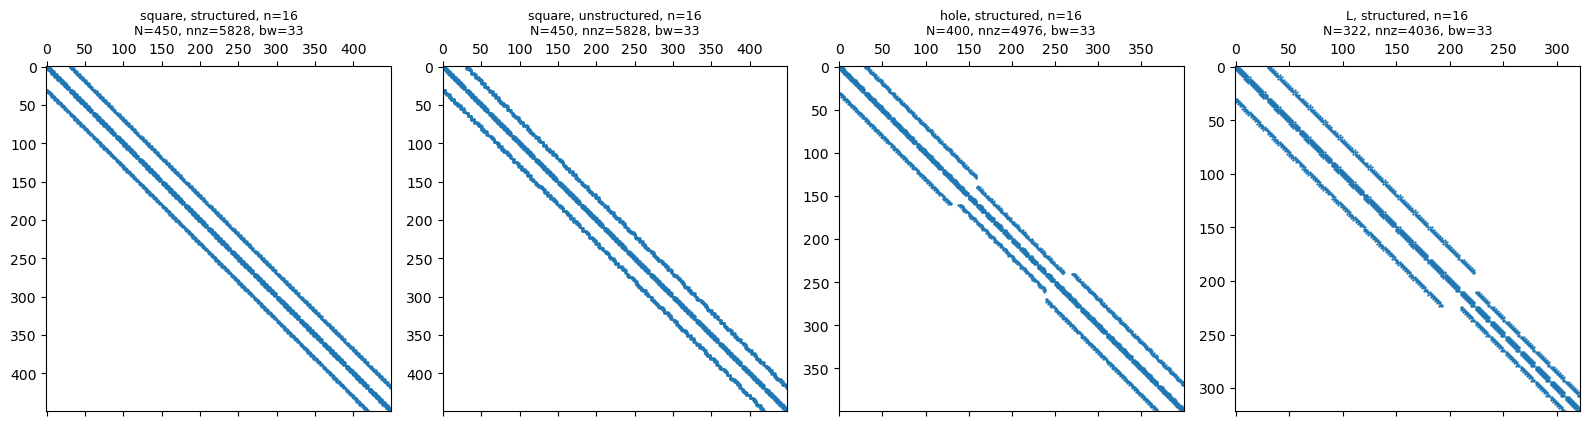

In [20]:
def bandwidth(M):
    M = M.tocoo()
    return int(np.abs(M.row - M.col).max())

def row_counts(M):
    return np.diff(M.tocsr().indptr)

cases = [('square', 'structured'), ('square', 'unstructured'), ('hole', 'structured'), ('L', 'structured')]
fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (shape, kind) in zip(axs, cases):
    s = build_suite(shape, kind, 16)
    Kff = system_from_suite(s, 'all')['Kff']
    rc = row_counts(Kff)
    ax.spy(Kff, markersize=0.6); ax.grid(False)
    ax.set_title(f"{shape}, {kind}, n=16\nN={Kff.shape[0]}, nnz={Kff.nnz}, bw={bandwidth(Kff)}", fontsize=9)
    print(f"{shape:6s} {kind:12s}: N={Kff.shape[0]:4d} nnz={Kff.nnz:6d} "
          f"mean/row={rc.mean():.2f} min={rc.min()} max={rc.max()} bw={bandwidth(Kff)}")
plt.tight_layout(); plt.show()

## 18. Density and memory growth

**Objective.** Why sparse storage is mandatory. For the structured `square` at increasing $n$, show
density $=$ nnz$/N^2$, the dense cost $8N^2$ bytes, and the sparse cost $\approx 12\cdot$nnz bytes.
**Output.** A table from $n=8$ to $n=128$.

In [21]:
rows = []
for n in [8, 16, 32, 64, 128]:
    s = build_suite('square', 'structured', n)
    Kff = system_from_suite(s, 'all')['Kff']
    N, nnz = Kff.shape[0], Kff.nnz
    rows.append(dict(n=n, N=N, nnz=nnz, density_pct=100*nnz/N**2,
                     dense_MB=8*N*N/1e6, sparse_MB=12*nnz/1e6))
print(pd.DataFrame(rows).round(4).to_string(index=False))

  n     N    nnz  density_pct  dense_MB  sparse_MB
  8    98   1156      12.0367    0.0768     0.0139
 16   450   5828       2.8780    1.6200     0.0699
 32  1922  25924       0.7018   29.5527     0.3111
 64  7938 109124       0.1732  504.0948     1.3095
128 32258 447556       0.0430 8324.6285     5.3707


## 19. Conditioning $\kappa(K_{ff})$ vs $h$

**Objective.** The key driver of iterative-solver cost. $\kappa=\lambda_{\max}/\lambda_{\min}$ of the
SPD reduced matrix, computed with ARPACK. For P1 elasticity $\kappa\sim h^{-2}$, so $\kappa$ should
roughly quadruple when $n$ doubles. **Output.** $\kappa$ and its growth rate per shape.

In [22]:
def cond_number(Kff):
    """kappa = lambda_max / lambda_min of an SPD matrix via ARPACK."""
    lmax = spla.eigsh(Kff, k=1, which='LM', return_eigenvectors=False)[0]
    lmin = spla.eigsh(Kff, k=1, sigma=0, which='LM', return_eigenvectors=False)[0]
    return lmax / lmin

rows = []
for shape in ['square', 'hole', 'L', 'U']:
    kappas = []
    for n in [8, 16, 32]:
        Kff = system_from_suite(build_suite(shape, 'structured', n), 'all')['Kff']
        kappas.append(cond_number(Kff.tocsc()))
    rate = [np.nan] + [np.log2(kappas[i]/kappas[i-1]) for i in range(1, len(kappas))]
    for n, k, r in zip([8, 16, 32], kappas, rate):
        rows.append(dict(shape=shape, n=n, h=1.0/n, kappa=k, rate_log2=r))
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\n(rate_log2 ~ 2 means kappa ~ h^-2)")

 shape  n     h   kappa  rate_log2
square  8 0.125  42.299        NaN
square 16 0.062 172.706      2.030
square 32 0.031 694.483      2.008
  hole  8 0.125  19.679        NaN
  hole 16 0.062  90.613      2.203
  hole 32 0.031 379.773      2.067
     L  8 0.125  26.578        NaN
     L 16 0.062 119.050      2.163
     L 32 0.031 494.035      2.053
     U  8 0.125  18.507        NaN
     U 16 0.062  84.403      2.189
     U 32 0.031 352.184      2.061

(rate_log2 ~ 2 means kappa ~ h^-2)


## 20. CG iterations vs refinement

**Objective.** Unpreconditioned conjugate gradients on the SPD $K_{ff}$. Iterations grow like
$\sqrt{\kappa}\sim h^{-1}$, so they roughly double when $n$ doubles — the headline reason
preconditioning matters. **Output.** CG iteration counts (tol $10^{-8}$) per shape and level, plus a
log–log figure of iterations vs $N$.

 shape  n    N  cg_iters
square  8   98        33
square 16  450        78
square 32 1922       159
  hole  8   80        26
  hole 16  400        63
  hole 32 1760       133
     L  8   66        33
     L 16  322        78
     L 32 1410       164
     U  8   68        30
     U 16  350        70
     U 32 1562       146


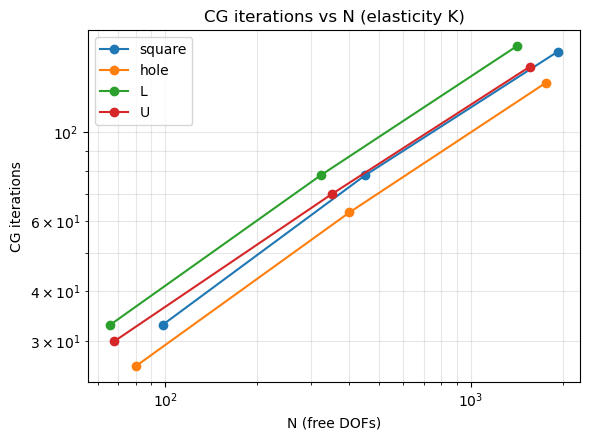

In [23]:
def cg_iterations(Kff, rhs, tol=1e-8, maxiter=20000):
    """Count CG iterations to reach relative residual < tol."""
    count = [0]
    def cb(xk):
        count[0] += 1
    spla.cg(Kff, rhs, rtol=tol, callback=cb, maxiter=maxiter)   # old SciPy (<1.12): tol=tol
    return count[0]

rows = []
for shape in ['square', 'hole', 'L', 'U']:
    for n in [8, 16, 32]:
        sysd = system_from_suite(build_suite(shape, 'structured', n), 'all')
        it = cg_iterations(sysd['Kff'], sysd['Fff'])
        rows.append(dict(shape=shape, n=n, N=sysd['Kff'].shape[0], cg_iters=it))
df = pd.DataFrame(rows)
print(df.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4.5))
for shape in ['square', 'hole', 'L', 'U']:
    sub = df[df['shape'] == shape]
    ax.loglog(sub['N'], sub['cg_iters'], 'o-', label=shape)
ax.set(xlabel='N (free DOFs)', ylabel='CG iterations', title='CG iterations vs N (elasticity K)')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## 21. Effect of mesh quality on $\kappa$ and CG

**Objective.** The distortion study, on the elasticity $K$. `quality` gives, per triangle, the
smallest/largest angle and $q=4\sqrt3\,A/\sum \ell^2$ ($q=1$ equilateral). As meshes get more
distorted the smallest angle shrinks, $\kappa$ grows and CG takes more iterations.

**Output.** A table over structured / unstructured / distorted meshes at $n=32$, plus a histogram of
the smallest angles.

        kind  jitter  min_angle  max_angle  q_min  below20    kappa  cg
  structured     0.0     45.000     90.000  0.866        0  694.483 159
unstructured     0.3     17.382    123.972  0.492        4  637.862 179
   distorted     0.2     21.049    135.728  0.444        0  812.621 203
   distorted     0.3      9.158    158.438  0.216      111 1349.510 242


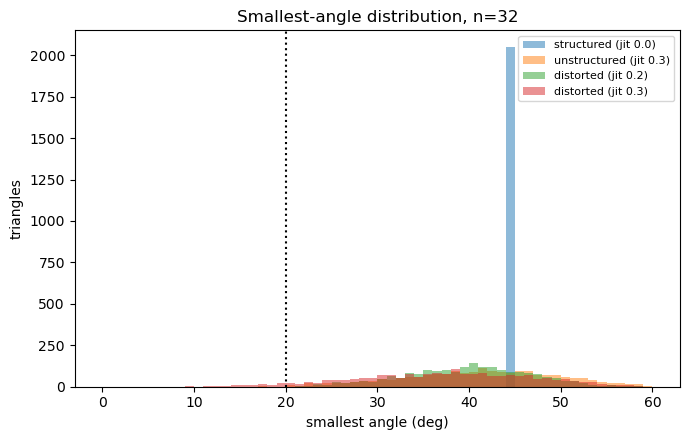

In [24]:
def quality(nodes, elements):
    """Per triangle: min angle (deg), max angle (deg), q = 4 sqrt3 A / sum(edge^2)."""
    P = nodes[elements]
    vv = np.stack([P[:, 1] - P[:, 0], P[:, 2] - P[:, 1], P[:, 0] - P[:, 2]], axis=1)
    l2 = (vv**2).sum(2)
    area = 0.5 * np.abs(vv[:, 0, 0]*vv[:, 1, 1] - vv[:, 0, 1]*vv[:, 1, 0])
    q = 4*np.sqrt(3)*area / l2.sum(1)
    l = np.sqrt(l2); L = l[:, [1, 2, 0]]; M = l[:, [2, 0, 1]]
    ang = np.degrees(np.arccos(np.clip((L**2 + M**2 - l**2)/(2*L*M), -1, 1)))
    return ang.min(1), ang.max(1), q

n = 32
kinds_jitters = [('structured', 0.0), ('unstructured', 0.3), ('distorted', 0.2), ('distorted', 0.3)]
rows = []
fig, ax = plt.subplots(figsize=(7, 4.5))
for kind, jit in kinds_jitters:
    nodes, elements, bnodes = generate_mesh(kind, n, jitter=jit)
    amin, amax, q = quality(nodes, elements)
    D = material_matrix(E_MOD, NU, 'plane_strain')
    K = assemble_stiffness_elasticity(nodes, elements, D)
    F = assemble_load_vector(nodes, elements, gravity_load())
    fixed = fixed_dofs(nodes, bnodes, 'all')
    Kff, Fff, _ = apply_bc(K, F, fixed)
    rows.append(dict(kind=kind, jitter=jit, min_angle=amin.min(), max_angle=amax.max(),
                     q_min=q.min(), below20=int((amin < 20).sum()),
                     kappa=cond_number(Kff), cg=cg_iterations(Kff, Fff)))
    ax.hist(amin, bins=np.linspace(0, 60, 61), alpha=0.5, label=f'{kind} (jit {jit})')
print(pd.DataFrame(rows).round(3).to_string(index=False))
ax.axvline(20, color='k', ls=':'); ax.set(xlabel='smallest angle (deg)', ylabel='triangles',
                                           title='Smallest-angle distribution, n=32')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

---
# Part 4 — Verification

Two kinds of correctness check: (a) the **elasticity** assembly reproduces a known field and
converges in energy; (b) the FE machinery itself converges at the textbook rate, shown on the
**scalar Poisson** problem where an exact solution is available. The Poisson problem is *solved* here,
not just assembled.

## 22. Elasticity checks: symmetry, SPD, zero row-sum, patch test

**Objective.** Four assembly correctness tests on `square`, $n=8$:

- **symmetry** $\|K-K^\top\|/\|K\|\approx 0$.
- **zero row-sum** of the *unconstrained* $K$ (rigid-body translation costs no energy).
- **SPD** of $K_{ff}$: smallest eigenvalue $>0$.
- **patch test**: impose a linear field $u=(x,0)$ on the boundary; P1 elements reproduce it exactly
  (constant strain), so the interior solution error is at round-off.

**Output.** PASS/FAIL with the measured quantity for each.

In [25]:
def check_spd(Kff, k=6):
    kk = min(k, Kff.shape[0] - 2)
    if kk < 1:
        vals = np.linalg.eigvalsh(Kff.toarray()); return bool((vals > 0).all()), float(vals.min())
    vals = spla.eigsh(Kff.tocsc(), k=kk, sigma=0, which='LM', return_eigenvectors=False)
    return bool((vals > 0).all()), float(vals.min())

def patch_test(nodes, elements, boundary_nodes, D, tol=1e-9):
    """Impose u=(x,0) on the boundary; interior should reproduce it exactly."""
    nv = len(nodes)
    d_exact = np.zeros(2 * nv); d_exact[0::2] = nodes[:, 0]
    K = assemble_stiffness_elasticity(nodes, elements, D).tocsc()
    fixed = fixed_dofs(nodes, boundary_nodes, 'all')
    free = np.setdiff1d(np.arange(2 * nv), fixed)
    F_free = -K[free][:, fixed] @ d_exact[fixed]
    d_sol = spla.spsolve(K[free][:, free].tocsc(), F_free)
    err = np.abs(d_sol - d_exact[free]).max()
    return err < tol, err

D = material_matrix(E_MOD, NU, 'plane_strain')
v, e, b = generate_mesh('structured', 8)
K = assemble_stiffness_elasticity(v, e, D)
F = assemble_load_vector(v, e, gravity_load())
Kff, Fff, free = apply_bc(K, F, fixed_dofs(v, b, 'all'))

sym = spla.norm(K - K.T) / spla.norm(K)
rowsum = np.abs(np.asarray(K.sum(axis=1)).ravel()).max()
spd_ok, lam_min = check_spd(Kff)
pt_ok, pt_err = patch_test(v, e, b, D)
print(f"symmetry  : {'PASS' if sym < 1e-10 else 'FAIL'}  (||K-K^T||/||K|| = {sym:.2e})")
print(f"row sum=0 : {'PASS' if rowsum < 1e-9 else 'FAIL'}  (max |row sum| = {rowsum:.2e})")
print(f"SPD(Kff)  : {'PASS' if spd_ok else 'FAIL'}  (lambda_min = {lam_min:.4e})")
print(f"patch test: {'PASS' if pt_ok else 'FAIL'}  (max error = {pt_err:.2e})")

symmetry  : PASS  (||K-K^T||/||K|| = 0.00e+00)
row sum=0 : PASS  (max |row sum| = 3.33e-16)
SPD(Kff)  : PASS  (lambda_min = 2.4173e-01)
patch test: PASS  (max error = 4.44e-16)


## 23. Elasticity compliance convergence

**Objective.** With no analytic displacement for the square under gravity, convergence is shown via
the **compliance** $C_h=F^\top d$ (the strain energy $\times 2$), which converges as the mesh refines.
We clamp the whole boundary and refine. **Output.** $C_h$ per level and the successive differences
(which shrink, confirming convergence).

In [26]:
def compliance(shape, kind, n, bc_mode='all'):
    sysd = system_from_suite(build_suite(shape, kind, n), bc_mode)
    d_free = spla.spsolve(sysd['Kff'], sysd['Fff'])
    return float(sysd['Fff'] @ d_free)

for shape in ['square', 'L']:
    C = [compliance(shape, 'structured', n) for n in [8, 16, 32, 64]]
    dC = np.diff(C)
    print(f"{shape:6s} C_h = {[f'{c:.6e}' for c in C]}")
    print(f"       diffs = {[f'{d:.3e}' for d in dC]}  (shrinking => converging)")

square C_h = ['3.850604e+00', '4.025612e+00', '4.073899e+00', '4.086576e+00']
       diffs = ['1.750e-01', '4.829e-02', '1.268e-02']  (shrinking => converging)
L      C_h = ['1.494236e+00', '1.660643e+00', '1.714611e+00', '1.732186e+00']
       diffs = ['1.664e-01', '5.397e-02', '1.758e-02']  (shrinking => converging)


## 24. Scalar-Poisson convergence check (solved)

**Objective.** Prove the FE machinery converges at the right rate on a problem with a known exact
solution: $-\Delta u=f$ on $[0,1]^2$, $u=0$ on $\partial\Omega$, with
$u_{ex}=\sin(\pi x)\sin(\pi y)$. This reuses the shared `tri_geometry` for the scalar P1 stiffness and
a 6-point quadrature for the load and the error norms. We **solve** each level and measure the $L^2$
and $H^1$ errors; the expected rates are 2 and 1.

**Output.** A table of $N$, $L^2$ error + rate, $H^1$ error + rate, and a log–log convergence figure.

 n    N          h         L2         H1  rate_L2    rate_H1
 8   49 1.7678e-01 2.1134e-02 4.3180e-01      NaN        NaN
16  225 8.8388e-02 5.3775e-03 2.1754e-01    1.975 9.8910e-01
32  961 4.4194e-02 1.3504e-03 1.0898e-01    1.994 9.9725e-01
64 3969 2.2097e-02 3.3799e-04 5.4514e-02    1.998 9.9931e-01

expected rates: L2 ~ 2, H1 ~ 1


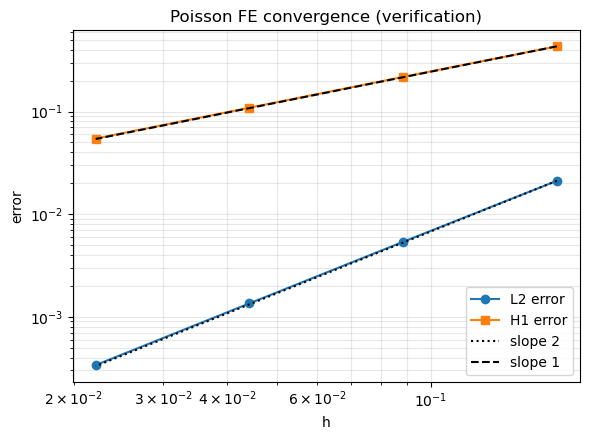

In [27]:
# exact solution of -Laplace(u)=f, u=0 on the boundary
u_ex  = lambda x, y: np.sin(np.pi*x)*np.sin(np.pi*y)
gu_ex = lambda x, y: (np.pi*np.cos(np.pi*x)*np.sin(np.pi*y), np.pi*np.sin(np.pi*x)*np.cos(np.pi*y))
f_ex  = lambda x, y: 2*np.pi**2*np.sin(np.pi*x)*np.sin(np.pi*y)

# 6-point quadrature on the reference triangle (degree-4 exact; weights sum to 1)
_a, _b, _c, _d = 0.816847572980459, 0.091576213509771, 0.108103018168070, 0.445948490915965
QL = np.array([[_a,_b,_b],[_b,_a,_b],[_b,_b,_a],[_c,_d,_d],[_d,_c,_d],[_d,_d,_c]])
QW = np.array([0.109951743655322]*3 + [0.223381589678011]*3)

def assemble_poisson(nodes, elements, k=1.0):
    """Scalar P1 Laplacian, reusing the shared tri_geometry (b, c, A)."""
    _, b, c, A = tri_geometry(nodes, elements)
    Ke = k/(4*A)[:, None, None]*(b[:, :, None]*b[:, None, :] + c[:, :, None]*c[:, None, :])
    I = np.broadcast_to(elements[:, :, None], Ke.shape).ravel()
    J = np.broadcast_to(elements[:, None, :], Ke.shape).ravel()
    return sp.coo_matrix((Ke.ravel(), (I, J)), shape=(len(nodes), len(nodes))).tocsr()

def poisson_load(nodes, elements, f):
    P, _, _, A = tri_geometry(nodes, elements)
    rhs = np.zeros(len(nodes))
    for L, w in zip(QL, QW):
        pts = np.einsum('i,eik->ek', L, P)
        fv = f(pts[:, 0], pts[:, 1])
        for i in range(3):
            np.add.at(rhs, elements[:, i], w*A*fv*L[i])
    return rhs

def poisson_errors(nodes, elements, d, u, gradu):
    P, b, c, A = tri_geometry(nodes, elements)
    de = d[elements]
    guh = np.column_stack([(de*b).sum(1), (de*c).sum(1)]) / (2*A)[:, None]
    e2 = h2 = 0.0
    for L, w in zip(QL, QW):
        pts = np.einsum('i,eik->ek', L, P)
        e2 += (w*A*(u(pts[:, 0], pts[:, 1]) - de @ L)**2).sum()
        gx, gy = gradu(pts[:, 0], pts[:, 1])
        h2 += (w*A*((gx-guh[:, 0])**2 + (gy-guh[:, 1])**2)).sum()
    return np.sqrt(e2), np.sqrt(h2)

levels = [8, 16, 32, 64]
rows = []
for n in levels:
    nodes, elements, bnodes = generate_mesh('structured', n)
    K = assemble_poisson(nodes, elements)
    rhs = poisson_load(nodes, elements, f_ex)
    free = np.setdiff1d(np.arange(len(nodes)), bnodes)
    d = np.zeros(len(nodes))
    d[free] = spla.spsolve(K[free][:, free].tocsc(), rhs[free])     # <-- solved
    eL2, eH1 = poisson_errors(nodes, elements, d, u_ex, gu_ex)
    rows.append(dict(n=n, N=len(free), h=np.sqrt(2)/n, L2=eL2, H1=eH1))
for i in range(len(rows)):
    rows[i]['rate_L2'] = np.nan if i == 0 else np.log2(rows[i-1]['L2']/rows[i]['L2'])
    rows[i]['rate_H1'] = np.nan if i == 0 else np.log2(rows[i-1]['H1']/rows[i]['H1'])
df = pd.DataFrame(rows)
print(df.to_string(index=False, float_format=lambda x: f'{x:.4e}' if abs(x) < 1 else f'{x:.3f}'))
print("\nexpected rates: L2 ~ 2, H1 ~ 1")

hh = df['h'].values
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(hh, df['L2'], 'o-', label='L2 error')
ax.loglog(hh, df['H1'], 's-', label='H1 error')
ax.loglog(hh, df['L2'].iloc[0]*(hh/hh[0])**2, 'k:', label='slope 2')
ax.loglog(hh, df['H1'].iloc[0]*(hh/hh[0]),    'k--', label='slope 1')
ax.set(xlabel='h', ylabel='error', title='Poisson FE convergence (verification)')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

---
# Part 5 — Supports under gravity

The physics the project is about: how the **support condition** changes the deformation. Same
geometry (`square`), same gravity load, two clamps:

- **whole-boundary-clamped** (`mode='all'`) — the sheet is pinned all around; it can only sag slightly
  in the interior.
- **bottom-edge-clamped** (`mode='bottom'`) — only $y=0$ is held; the sheet hangs and sags far more.

We solve both, compare peak displacement and compliance, and plot the deformed shapes and the von
Mises stress.

## 25. Solve both support cases

**Objective.** Solve $K_{ff}d_f=f_f$ for each clamp on `square`, $n=32$, and report free-DOF count,
peak $|u|$, compliance $C=F^\top d$, and the solver residual. **Output.** A comparison table.

In [28]:
def solve_case(shape, kind, n, bc_mode, model='plane_strain'):
    s = build_suite(shape, kind, n)
    sysd = system_from_suite(s, bc_mode, model)
    d_free = spla.spsolve(sysd['Kff'], sysd['Fff'])
    d = np.zeros(sysd['K'].shape[0]); d[sysd['free']] = d_free
    res = np.linalg.norm(sysd['Kff'] @ d_free - sysd['Fff']) / (np.linalg.norm(sysd['Fff']) + 1e-30)
    ux, uy = d[0::2], d[1::2]
    mag = np.sqrt(ux**2 + uy**2)
    return dict(sysd=sysd, d=d, ux=ux, uy=uy, mag=mag,
                summary=dict(bc=bc_mode, N_free=sysd['Kff'].shape[0], peak_disp=mag.max(),
                             compliance=float(sysd['Fff'] @ d_free), residual=res))

cases = {m: solve_case('square', 'structured', 32, m) for m in ['all', 'bottom']}
print(pd.DataFrame([cases[m]['summary'] for m in ['all', 'bottom']]).to_string(index=False))

    bc  N_free  peak_disp  compliance     residual
   all    1922   0.867138    4.073899 4.293075e-14
bottom    2112   4.373812   27.338727 2.957088e-13


## 26. Deformed-shape comparison

**Objective.** Visualise the two solutions. We draw the undeformed mesh (grey) and the deformed mesh
(nodes moved by an amplified displacement) coloured by $|u|$. The bottom-clamped sheet should sag
much more. **Output.** Two side-by-side deformation plots.

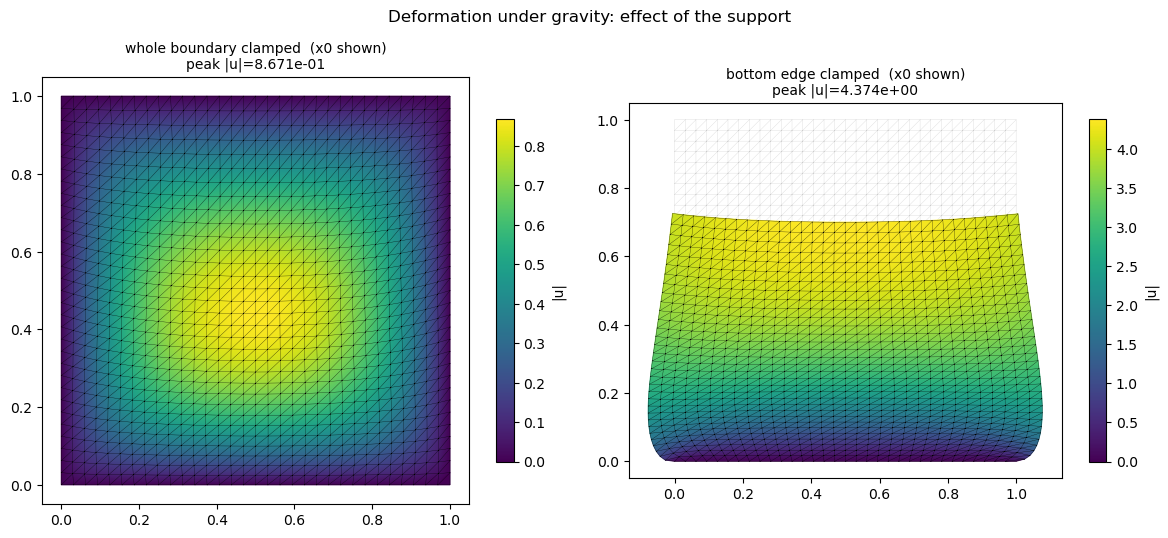

In [29]:
def plot_deformed(ax, case, title, scale):
    sysd = case['sysd']; nodes = sysd['suite']['nodes']; elements = sysd['suite']['elements']
    ax.triplot(nodes[:, 0], nodes[:, 1], elements, lw=0.2, color='0.8')
    defo = nodes + scale * np.column_stack([case['ux'], case['uy']])
    tpc = ax.tripcolor(defo[:, 0], defo[:, 1], elements, case['mag'], shading='gouraud', cmap='viridis')
    ax.triplot(defo[:, 0], defo[:, 1], elements, lw=0.2, color='k')
    ax.set_aspect('equal'); ax.set_title(title, fontsize=10)
    return tpc

# common amplification so the two panels are comparable
scale = 0.3 / max(cases['all']['mag'].max(), cases['bottom']['mag'].max())
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
labels = {'all': 'whole boundary clamped', 'bottom': 'bottom edge clamped'}
for ax, m in zip(axs, ['all', 'bottom']):
    tpc = plot_deformed(ax, cases[m], f"{labels[m]}  (x{scale:.0f} shown)\npeak |u|={cases[m]['mag'].max():.3e}", scale)
    fig.colorbar(tpc, ax=ax, shrink=0.8, label='|u|')
plt.suptitle("Deformation under gravity: effect of the support", y=1.02)
plt.tight_layout(); plt.show()

## 27. Von Mises stress fields

**Objective.** Where the material is most loaded. From the solution, element strain
$\varepsilon=B\,d_e$, stress $\sigma=D\varepsilon$, and the von Mises scalar
$\sigma_{vm}=\sqrt{\sigma_{xx}^2-\sigma_{xx}\sigma_{yy}+\sigma_{yy}^2+3\tau_{xy}^2}$. Reuses the shared
`strain_displacement_B`. **Output.** Peak von Mises per case + two stress maps.

whole boundary clamped  : peak von Mises = 3.7273e+00, mean = 1.9026e+00
bottom edge clamped     : peak von Mises = 1.5592e+01, mean = 4.7526e+00


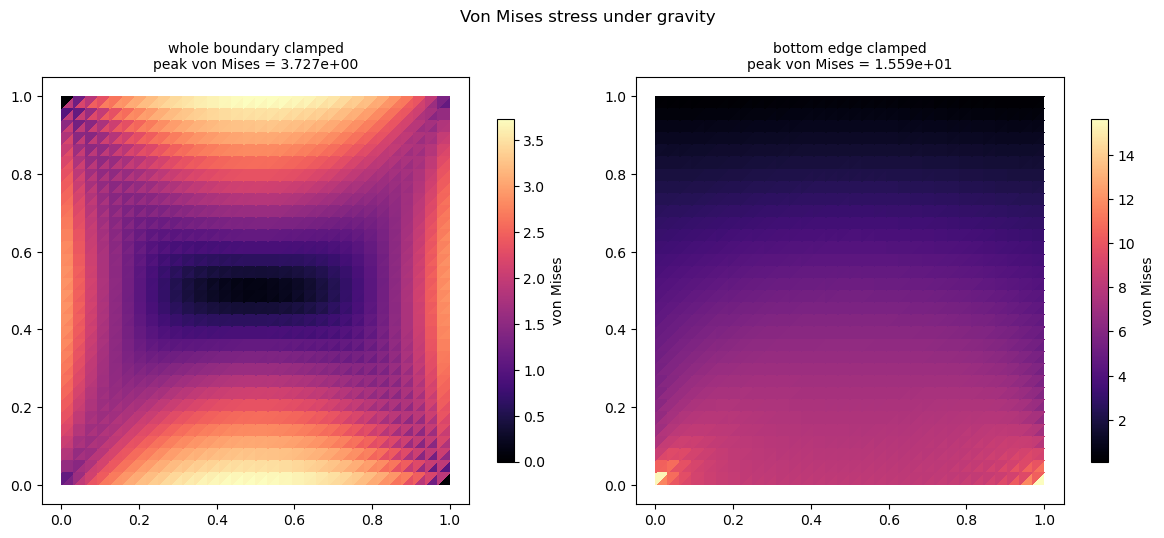

In [30]:
def element_stresses(nodes, elements, d, D):
    """Constant per-triangle stress sigma = D B d_e, reusing the shared B."""
    _, b, c, A = tri_geometry(nodes, elements)
    B = strain_displacement_B(b, c, A)
    nt = len(elements)
    de = np.zeros((nt, 6))
    for i in range(3):
        de[:, 2*i]     = d[2 * elements[:, i]]
        de[:, 2*i + 1] = d[2 * elements[:, i] + 1]
    eps = np.einsum('eij,ej->ei', B, de)
    return (D @ eps.T).T          # (n_t, 3) = [sxx, syy, txy]

def von_mises(sigma):
    sxx, syy, txy = sigma[:, 0], sigma[:, 1], sigma[:, 2]
    return np.sqrt(sxx**2 - sxx*syy + syy**2 + 3*txy**2)

D = material_matrix(E_MOD, NU, 'plane_strain')
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, m in zip(axs, ['all', 'bottom']):
    case = cases[m]; sysd = case['sysd']
    nodes, elements = sysd['suite']['nodes'], sysd['suite']['elements']
    vm = von_mises(element_stresses(nodes, elements, case['d'], D))
    tpc = ax.tripcolor(nodes[:, 0], nodes[:, 1], elements, facecolors=vm, cmap='magma')
    ax.set_aspect('equal'); ax.set_title(f"{labels[m]}\npeak von Mises = {vm.max():.3e}", fontsize=10)
    fig.colorbar(tpc, ax=ax, shrink=0.8, label='von Mises')
    print(f"{labels[m]:24s}: peak von Mises = {vm.max():.4e}, mean = {vm.mean():.4e}")
plt.suptitle("Von Mises stress under gravity", y=1.02)
plt.tight_layout(); plt.show()

## Part 6 — Solving the systems (direct & iterative solvers)

> Sections 28 onward solve the reduced SPD systems $K_{ff}\,\mathbf{d}_f=\mathbf{f}_f$ built above, and compare direct and iterative methods across the whole experiment set. Everything here reuses Part 1 (meshes) and Part 2 (`system_from_suite`) unchanged — **no new matrices are created.**

### 28. Build the full matrix zoo

**Objective.** Assemble every reduced system once into a single dict `ZOO`, keyed by a string `matrix_id`. Every solver in Parts 6A/6B reads from `ZOO`, so each method acts on *identical* inputs and the timings are comparable.

**What is done.** The zoo is the full `EXPERIMENT_MATRIX` (4 shapes × 3 kinds × 3 levels = 36 systems, whole-boundary clamp, $
u=0.3$), **plus** two controlled variants layered on the finest structured meshes through knobs that already exist:
- a **support variant** — the four shapes at level 32, structured, clamped only on the bottom edge (`bc_mode='bottom'`);
- a **material variant** — the four shapes at level 32, structured, with a near-incompressible $
u=0.49$ (same mesh, only the constitutive matrix $D$ changes).

That gives **44 systems**. Each `ZOO[matrix_id]` stores the assembled `sysd` (with `Kff`, `Fff`, `free`, `K`, `F`, `D`) plus its five descriptive axes (`shape, kind, level, bc, nu`), so the final analysis can `groupby` any of them.

**Why it matters.** Single source of truth: assembling here and nowhere else is what makes the solver comparison fair. Keeping *every* system (not a sample) is what lets us later explain *why* a method is slow or inaccurate on a given matrix.

**Output.** A table of all 44 systems (`matrix_id, shape, kind, level, bc, nu, N, nnz`) and the size of the largest system.

In [31]:
def _suite_with_nu(suite, nu):
    s = dict(suite)
    s['nu'] = nu
    return s

def make_zoo():
    zoo = {}
    def add(matrix_id, suite, bc, nu):
        sysd = system_from_suite(suite, bc_mode=bc, model='plane_strain')
        sysd['matrix_id'] = matrix_id
        sysd['shape'] = suite['shape']
        sysd['kind'] = suite['kind']
        sysd['level'] = suite['level']
        sysd['bc'] = bc
        sysd['nu'] = nu
        zoo[matrix_id] = sysd
    for shape, kind, level in EXPERIMENT_MATRIX:
        add(shape + "_" + kind + "_" + str(level), build_suite(shape, kind, level), 'all', NU)
    for shape in ['square', 'hole', 'L', 'U']:
        add(shape + "_structured_32_bottom", build_suite(shape, 'structured', 32), 'bottom', NU)
    for shape in ['square', 'hole', 'L', 'U']:
        add(shape + "_structured_32_nu049",
            _suite_with_nu(build_suite(shape, 'structured', 32), 0.49), 'all', 0.49)
    return zoo

ZOO = make_zoo()

zoo_rows = []
for mid, s in ZOO.items():
    zoo_rows.append({'matrix_id': mid, 'shape': s['shape'], 'kind': s['kind'],
                     'level': s['level'], 'bc': s['bc'], 'nu': s['nu'],
                     'N': s['Kff'].shape[0], 'nnz': s['Kff'].nnz})
zoo_df = pd.DataFrame(zoo_rows)
print(zoo_df.to_string(index=False))

big = zoo_df.loc[zoo_df['N'].idxmax()]
print("")
print(str(len(ZOO)) + " systems in the zoo.")
print("Largest: " + str(big['matrix_id']) + " with N = " + str(big['N']) + ", nnz = " + str(big['nnz']) + ".")


                  matrix_id  shape         kind  level     bc   nu    N   nnz
        square_structured_8 square   structured      8    all 0.30   98  1156
       square_structured_16 square   structured     16    all 0.30  450  5828
       square_structured_32 square   structured     32    all 0.30 1922 25924
         square_distorted_8 square    distorted      8    all 0.30   98  1156
        square_distorted_16 square    distorted     16    all 0.30  450  5828
        square_distorted_32 square    distorted     32    all 0.30 1922 25924
      square_unstructured_8 square unstructured      8    all 0.30   98  1156
     square_unstructured_16 square unstructured     16    all 0.30  450  5828
     square_unstructured_32 square unstructured     32    all 0.30 1922 25924
          hole_structured_8   hole   structured      8    all 0.30   80   816
         hole_structured_16   hole   structured     16    all 0.30  400  4976
         hole_structured_32   hole   structured     32    all 0.

## 29. Initialize the master `RESULTS` table 

**Objective.** Create the single DataFrame every solver appends to — created once, never
reset. Accuracy is tracked by both the relative residual $\rho$ and the relative error $e$
against the direct (Cholesky) reference, since a small residual need not mean a small error
on an ill-conditioned matrix ($e\lesssim\kappa\,\rho$).

**Output.** The empty table's columns and the common tolerance `TOL`.

In [32]:
RESULTS_COLUMNS = [
    'method', 'matrix_id', 'shape', 'kind', 'level', 'bc', 'nu',
    'N', 'nnz', 'symmetric', 'spd', 'kappa',
    'setup_time_s', 'solve_time_s', 'total_time_s',
    'iterations', 'tol', 'final_residual', 'rel_error',
    'speedup_vs_direct', 'converged',
]

RESULTS = pd.DataFrame(columns=RESULTS_COLUMNS)
TOL = 1e-8   # common relative-residual tolerance for all iterative methods

def record_result(method, sysd, setup_time_s=0.0, solve_time_s=0.0,
                  iterations=np.nan, final_residual=np.nan, rel_error=np.nan,
                  tol=np.nan, converged=True):
    global RESULTS
    row = {
        'method': method, 'matrix_id': sysd['matrix_id'],
        'shape': sysd['shape'], 'kind': sysd['kind'], 'level': sysd['level'],
        'bc': sysd['bc'], 'nu': sysd['nu'],
        'N': sysd['Kff'].shape[0], 'nnz': sysd['Kff'].nnz,
        'symmetric': sysd.get('symmetric', np.nan), 'spd': sysd.get('spd', np.nan),
        'kappa': sysd.get('kappa', np.nan),
        'setup_time_s': setup_time_s, 'solve_time_s': solve_time_s,
        'total_time_s': setup_time_s + solve_time_s,
        'iterations': iterations, 'tol': tol,
        'final_residual': final_residual, 'rel_error': rel_error,
        'speedup_vs_direct': np.nan, 'converged': converged,
    }
    RESULTS = pd.concat([RESULTS, pd.DataFrame([row])], ignore_index=True)
    return row

print("RESULTS initialized:", len(RESULTS_COLUMNS), "columns,", len(RESULTS), "rows.")
print("columns:", list(RESULTS.columns))
print("common iterative tolerance TOL =", format(TOL, '.0e'))

RESULTS initialized: 21 columns, 0 rows.
columns: ['method', 'matrix_id', 'shape', 'kind', 'level', 'bc', 'nu', 'N', 'nnz', 'symmetric', 'spd', 'kappa', 'setup_time_s', 'solve_time_s', 'total_time_s', 'iterations', 'tol', 'final_residual', 'rel_error', 'speedup_vs_direct', 'converged']
common iterative tolerance TOL = 1e-08


## 30

**Objective.** Characterise every matrix (symmetric? SPD? $\kappa$? bandwidth?) and cache the
condition number onto each `ZOO` entry so later cells never recompute it. Also precompute the
**direct reference solution** $\mathbf{d}^\star$ (sparse Cholesky-equivalent via `spsolve`) for
every system — this is the accuracy oracle for the iterative errors.

$\kappa$ is computed as $\sigma_{\max}/\sigma_{\min}$ with ARPACK; for the SPD $K_{ff}$ the
singular values equal the eigenvalues, so this is the 2-norm condition number.

**Output.** A property table and a `groupby` summary of mean $\kappa$ by level / kind.

In [33]:
def cond_number(Kff):
    Kff = Kff.tocsc()
    lmax = spla.eigsh(Kff, k=1, which='LM', return_eigenvectors=False)[0]
    lmin = spla.eigsh(Kff, k=1, sigma=0, which='LM', return_eigenvectors=False)[0]
    return float(lmax / lmin)

def bandwidth(M):
    M = M.tocoo()
    return int(np.abs(M.row - M.col).max())

D_DIRECT = {}   # matrix_id -> reference solution d_f (direct)
prop_rows = []
for mid, s in ZOO.items():
    Kff = s['Kff']
    sym = spla.norm(Kff - Kff.T) / spla.norm(Kff)
    kappa = cond_number(Kff)
    # smallest eigenvalue already > 0 for SPD; confirm via sigma=0 solve succeeding
    lmin = spla.eigsh(Kff.tocsc(), k=1, sigma=0, which='LM', return_eigenvectors=False)[0]
    spd = bool(lmin > 0)
    s['symmetric'] = bool(sym < 1e-10)
    s['spd'] = spd
    s['kappa'] = kappa
    D_DIRECT[mid] = spla.spsolve(Kff, s['Fff'])
    prop_rows.append({'matrix_id': mid, 'N': Kff.shape[0], 'nnz': Kff.nnz,
                      'symmetric': s['symmetric'], 'spd': spd,
                      'kappa': round(kappa, 1), 'bandwidth': bandwidth(Kff)})
prop_df = pd.DataFrame(prop_rows)
print(prop_df.to_string(index=False))
print("")
print("mean kappa by level:")
print(prop_df.merge(zoo_df[['matrix_id', 'level', 'kind']], on='matrix_id')
      .groupby('level')['kappa'].mean().round(1).to_string())
print("")
print("mean kappa by kind:")
print(prop_df.merge(zoo_df[['matrix_id', 'level', 'kind']], on='matrix_id')
      .groupby('kind')['kappa'].mean().round(1).to_string())

                  matrix_id    N   nnz  symmetric  spd   kappa  bandwidth
        square_structured_8   98  1156       True True    42.3         17
       square_structured_16  450  5828       True True   172.7         33
       square_structured_32 1922 25924       True True   694.5         65
         square_distorted_8   98  1156       True True    46.1         17
        square_distorted_16  450  5828       True True   202.8         33
        square_distorted_32 1922 25924       True True   964.9         65
      square_unstructured_8   98  1156       True True    33.4         17
     square_unstructured_16  450  5828       True True   176.1         33
     square_unstructured_32 1922 25924       True True   637.9         65
          hole_structured_8   80   816       True True    19.7         17
         hole_structured_16  400  4976       True True    90.6         33
         hole_structured_32 1760 23376       True True   379.8         65
           hole_distorted_8   80   816

## 31. Accuracy helper

**Objective.** One function to score any solver output against the direct reference: the
relative residual $\rho$ and the relative error $e$ vs $\mathbf{d}^\star$.

In [34]:
def solver_errors(sysd, d):
    Kff, Fff = sysd['Kff'], sysd['Fff']
    rho = np.linalg.norm(Fff - Kff @ d) / (np.linalg.norm(Fff) + 1e-30)
    dstar = D_DIRECT[sysd['matrix_id']]
    e = np.linalg.norm(d - dstar) / (np.linalg.norm(dstar) + 1e-30)
    return float(rho), float(e)

# sanity check on one system: the direct reference has ~0 residual and 0 self-error
_s = ZOO['square_structured_8']
print("reference check (square_structured_8):", solver_errors(_s, D_DIRECT['square_structured_8']))

reference check (square_structured_8): (1.8584960752574913e-15, 0.0)


# Part 6A — Direct solvers

Sections 32–34b solve the reduced SPD systems $K_{ff}\,d_f = f_f$ of the matrix zoo (Section 28) with **direct** methods and record cost and accuracy into the shared `RESULTS` table (Section 29). Everything here reuses Part 1 (meshes), Part 2 (`system_from_suite`), the zoo `ZOO`, the reference solution `D_DIRECT` and the helper `solver_errors` **unchanged** — no new matrices are created.

Three direct methods, mapped to the syllabus:

- **LU with partial pivoting** (`scipy.sparse.linalg.splu`) — the general direct baseline, the time every iterative method in Part 6B must beat.
- **Cholesky** $K_{ff}=LL^\top$ (CHOLMOD if available, else LU-without-pivoting on the SPD matrix) — the SPD-specialised method, about half the work and storage of LU, and the accuracy reference the iterative errors are measured against.
- **QR** $K_{ff}=QR\Rightarrow Rd_f=Q^\top f_f$ (dense, `scipy.linalg.qr`) — a deliberately suboptimal control: accurate, but on a square SPD matrix it ignores symmetry, definiteness and sparsity, so it quantifies the penalty of using the wrong tool. Restricted to $N\lesssim 1000$ for memory.

Every method is timed with the shared protocol (factorisation and solve phases split, best-of-3 repeat on the fast solves) and appended to `RESULTS` with `record_result`, so the direct rows line up with the iterative rows by `matrix_id`.


## 32. LU factorization over the zoo

**Objective.** Sparse LU with partial pivoting on every system: factorization vs solve time, and the fill-in it produces.

**What is done.** `lu = splu(Kff.tocsc())` then `lu.solve(Fff)`. The two phases are timed separately (best-of-3 on the fast systems), and the fill ratio `nnz(L+U)/nnz(Kff)` is recorded. A preliminary print on the smallest system first, then the whole zoo; each row is appended to `RESULTS` with `method="lu"`.

**Why it matters.** LU is the general-purpose direct baseline. Its cost is dominated by the factorization, which grows with `N` and with fill-in — so this is where the geometry of the mesh starts to cost money.

**Interpretation.** Setup time $\gg$ solve time; both grow with `N`; the fill ratio is larger on unstructured meshes and on the re-entrant L/U shapes (irregular sparsity), which is the geometry effect on *direct* cost.

**Output.** A table over the zoo (`matrix_id`, `N`, `nnz`, `setup_time_s`, `solve_time_s`, `fill_ratio`, `residual`) and the appended `lu` rows.


In [35]:
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.sparse.linalg as spla

def _best_of(fn, repeat=3):
    """Return (result, best_elapsed_seconds) over `repeat` runs of fn()."""
    best = np.inf
    out = None
    for _ in range(repeat):
        t0 = time.perf_counter()
        out = fn()
        dt = time.perf_counter() - t0
        if dt < best:
            best = dt
    return out, best

def lu_solve_system(sysd, repeat=3):
    """Sparse LU (partial pivoting) via splu. Returns a metrics dict."""
    Kff = sysd["Kff"].tocsc()
    Fff = sysd["Fff"]

    # Factorization (do the heavy work once, then a light repeat for timing).
    lu, setup_t = _best_of(lambda: spla.splu(Kff), repeat=repeat)
    # Solve phase.
    d, solve_t = _best_of(lambda: lu.solve(Fff), repeat=repeat)

    fill = (lu.L.nnz + lu.U.nnz) / Kff.nnz
    rho, rel_err = solver_errors(sysd, d)
    return {
        "d": d,
        "setup_time_s": setup_t,
        "solve_time_s": solve_t,
        "fill_ratio": fill,
        "residual": rho,
        "rel_error": rel_err,
    }

# Preliminary on the smallest system, exactly as the iterative sections do.
_mid0 = min(ZOO, key=lambda m: ZOO[m]["Kff"].shape[0])
_r0 = lu_solve_system(ZOO[_mid0])
print(f"LU preliminary on {_mid0} (N={ZOO[_mid0]['Kff'].shape[0]}): "
      f"setup={_r0['setup_time_s']:.2e}s | solve={_r0['solve_time_s']:.2e}s | "
      f"fill={_r0['fill_ratio']:.2f} | residual={_r0['residual']:.2e}")

# Full zoo.
_lu_rows = []
for mid, sysd in ZOO.items():
    r = lu_solve_system(sysd)
    record_result(
        "lu", sysd,
        setup_time_s=r["setup_time_s"],
        solve_time_s=r["solve_time_s"],
        iterations=np.nan,
        final_residual=r["residual"],
        rel_error=r["rel_error"],
        tol=TOL,
        converged=True,
    )
    _lu_rows.append({
        "matrix_id": mid,
        "N": sysd["Kff"].shape[0],
        "nnz": sysd["Kff"].nnz,
        "setup_time_s": r["setup_time_s"],
        "solve_time_s": r["solve_time_s"],
        "fill_ratio": r["fill_ratio"],
        "residual": r["residual"],
    })

_lu_df = pd.DataFrame(_lu_rows)
print(f"LU: factored {len(_lu_df)} / {len(ZOO)} systems.")
print(_lu_df.round(6).to_string(index=False))


LU preliminary on L_structured_8 (N=66): setup=2.44e-04s | solve=2.84e-05s | fill=1.33 | residual=1.16e-15


/var/folders/z4/nl4m_8q17pxg6zl3ln3klpq00000gn/T/ipykernel_22404/322816895.py:29: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  RESULTS = pd.concat([RESULTS, pd.DataFrame([row])], ignore_index=True)


LU: factored 44 / 44 systems.
                  matrix_id    N   nnz  setup_time_s  solve_time_s  fill_ratio  residual
        square_structured_8   98  1156      0.000420      0.000035    2.043253       0.0
       square_structured_16  450  5828      0.001533      0.000303    3.596774       0.0
       square_structured_32 1922 25924      0.011551      0.000628    5.908810       0.0
         square_distorted_8   98  1156      0.000356      0.000020    2.046713       0.0
        square_distorted_16  450  5828      0.002683      0.000074    3.598833       0.0
        square_distorted_32 1922 25924      0.012180      0.000824    5.929872       0.0
      square_unstructured_8   98  1156      0.000304      0.000020    2.198962       0.0
     square_unstructured_16  450  5828      0.002036      0.000113    3.361359       0.0
     square_unstructured_32 1922 25924      0.015511      0.000651    6.136476       0.0
          hole_structured_8   80   816      0.000544      0.000030    1.723039  

## 33. Cholesky factorization over the zoo

**Objective.** The SPD-specific direct method (syllabus S13), used as the best direct reference.

**What is done.** If `sksparse.cholmod` is installed, `cholesky(Kff)` gives a true sparse Cholesky factor. Otherwise we fall back to `splu` on the SPD matrix: on a symmetric positive-definite matrix LU-without-pivoting coincides with $LL^\top$ up to a diagonal scaling, so the fallback measures the same work. Both phases are timed over the whole zoo, and we report the Cholesky-setup / LU-setup ratio per matrix.

**Why it matters.** Exploiting symmetry + positive-definiteness roughly halves LU's factorization work and storage — the concrete payoff of the properties tabulated in Section 29. This factor is also the accuracy oracle and the time-to-beat for every iterative method.

**Interpretation.** Cholesky setup is about half of LU setup at equal accuracy. On the same mesh the factorization cost barely changes between $
u=0.3$ and $
u=0.49$: ill-conditioning hurts the *iterative* solvers, not the direct ones (a preview of Part 6B).

**Output.** A table over the zoo plus a one-line Cholesky-setup / LU-setup ratio per matrix, and the appended `cholesky` rows.


In [36]:
# Prefer a true sparse Cholesky (CHOLMOD); fall back to splu on the SPD matrix.
try:
    from sksparse.cholmod import cholesky as _cholmod_cholesky
    _HAVE_CHOLMOD = True
except Exception:
    _HAVE_CHOLMOD = False

print("Cholesky backend:", "sksparse.cholmod (true sparse Cholesky)" if _HAVE_CHOLMOD else "splu fallback (LU-without-pivoting == Cholesky on SPD)")

def cholesky_solve_system(sysd, repeat=3):
    """SPD-specialised direct solve. Returns a metrics dict."""
    Kff = sysd["Kff"].tocsc()
    Fff = sysd["Fff"]

    if _HAVE_CHOLMOD:
        factor, setup_t = _best_of(lambda: _cholmod_cholesky(Kff), repeat=repeat)
        d, solve_t = _best_of(lambda: factor(Fff), repeat=repeat)
    else:
        # Fallback: splu on the SPD matrix. On a symmetric positive-definite
        # matrix LU-without-pivoting coincides with Cholesky up to a diagonal
        # scaling, so this measures the same ~N^3/3 factorization work. We ask
        # splu not to pivot off the diagonal (diag_pivot_thresh=0.0), which is
        # safe here precisely because Kff is SPD.
        factor, setup_t = _best_of(lambda: spla.splu(Kff, diag_pivot_thresh=0.0), repeat=repeat)
        d, solve_t = _best_of(lambda: factor.solve(Fff), repeat=repeat)

    rho, rel_err = solver_errors(sysd, d)
    return {
        "d": d,
        "setup_time_s": setup_t,
        "solve_time_s": solve_t,
        "residual": rho,
        "rel_error": rel_err,
    }

# Preliminary on the smallest system.
_c0 = cholesky_solve_system(ZOO[_mid0])
print(f"Cholesky preliminary on {_mid0}: setup={_c0['setup_time_s']:.2e}s | solve={_c0['solve_time_s']:.2e}s | residual={_c0['residual']:.2e}")

# Full zoo. We keep the LU setup times from Section 32 to form the ratio.
_lu_setup = {row["matrix_id"]: row["setup_time_s"] for row in _lu_rows}

_chol_rows = []
for mid, sysd in ZOO.items():
    r = cholesky_solve_system(sysd)
    record_result(
        "cholesky", sysd,
        setup_time_s=r["setup_time_s"],
        solve_time_s=r["solve_time_s"],
        iterations=np.nan,
        final_residual=r["residual"],
        rel_error=r["rel_error"],
        tol=TOL,
        converged=True,
    )
    _chol_rows.append({
        "matrix_id": mid,
        "N": sysd["Kff"].shape[0],
        "setup_time_s": r["setup_time_s"],
        "solve_time_s": r["solve_time_s"],
        "residual": r["residual"],
        "chol_setup / lu_setup": r["setup_time_s"] / _lu_setup[mid],
    })

_chol_df = pd.DataFrame(_chol_rows)
print(f"Cholesky: factored {len(_chol_df)} / {len(ZOO)} systems.")
print(_chol_df.round(6).to_string(index=False))
print(f"mean Cholesky-setup / LU-setup ratio = {_chol_df['chol_setup / lu_setup'].mean():.3f}  (expect < 1: Cholesky is the cheaper factorization)")


Cholesky backend: splu fallback (LU-without-pivoting == Cholesky on SPD)
Cholesky preliminary on L_structured_8: setup=2.35e-04s | solve=2.10e-05s | residual=1.16e-15
Cholesky: factored 44 / 44 systems.
                  matrix_id    N  setup_time_s  solve_time_s  residual  chol_setup / lu_setup
        square_structured_8   98      0.000454      0.000035       0.0               1.082081
       square_structured_16  450      0.001663      0.000076       0.0               1.084731
       square_structured_32 1922      0.014222      0.000797       0.0               1.231159
         square_distorted_8   98      0.000371      0.000020       0.0               1.042008
        square_distorted_16  450      0.001403      0.000159       0.0               0.522918
        square_distorted_32 1922      0.010995      0.000414       0.0               0.902707
      square_unstructured_8   98      0.000625      0.000021       0.0               2.056990
     square_unstructured_16  450      0.00151

## 34. QR factorization — the deliberately suboptimal direct method

**Objective.** Solve $K_{ff} d_f = f_f$ via $K_{ff}=QR\Rightarrow R\,d_f = Q^\top f_f$ and measure the penalty of a least-squares-oriented factorization on a square SPD matrix.

**What is done.** `scipy.linalg.qr` on the *dense* `Kff.toarray()` (SciPy has no sparse QR), then `solve_triangular(R, Q.T @ Fff)`. Factorization and back-substitution are timed separately. QR is restricted to systems with $N\lesssim 1000$, because the dense factor is $O(N^2)$ memory and $O(N^3)$ time; larger systems get a recorded row with `converged=True`, `total_time_s=NaN` and a printed "QR skipped (dense, too large)" note, reusing the same `matrix_id` keys so the table still lines up.

**Why it matters.** QR is numerically stable and *works*, but it is the wrong tool here: it discards symmetry, definiteness and sparsity. Making that explicit with timings is the cleanest demonstration of why Cholesky/CG are preferred for SPD systems, and it exercises the QR content of the course (S9–S10) on a real problem.

**Interpretation.** On the same matrix QR factorization costs roughly twice Cholesky (and far more once dense-vs-sparse storage is accounted for), while its accuracy (residual, `rel_error`) is as good as the other direct methods — so the lesson is "QR is accurate but wasteful here", not "QR is wrong".

**Output.** A table over the small/medium zoo, a QR-vs-Cholesky factorization-time figure, and a printed list of the systems QR was skipped on.


QR preliminary on L_structured_8: setup=4.75e-04s | solve=5.23e-05s | residual=2.23e-15
QR: solved 24 systems (N <= 1000); skipped 20.
             matrix_id   N  setup_time_s  solve_time_s  residual
   square_structured_8  98      0.000756      0.000115       0.0
  square_structured_16 450      0.116349      0.000368       0.0
    square_distorted_8  98      0.000407      0.000056       0.0
   square_distorted_16 450      0.109189      0.000359       0.0
 square_unstructured_8  98      0.000385      0.000054       0.0
square_unstructured_16 450      0.106529      0.000397       0.0
     hole_structured_8  80      0.000281      0.000049       0.0
    hole_structured_16 400      0.079088      0.000463       0.0
      hole_distorted_8  80      0.000309      0.000049       0.0
     hole_distorted_16 400      0.073331      0.000282       0.0
   hole_unstructured_8  80      0.000274      0.000048       0.0
  hole_unstructured_16 400      0.075905      0.000283       0.0
        L_structured

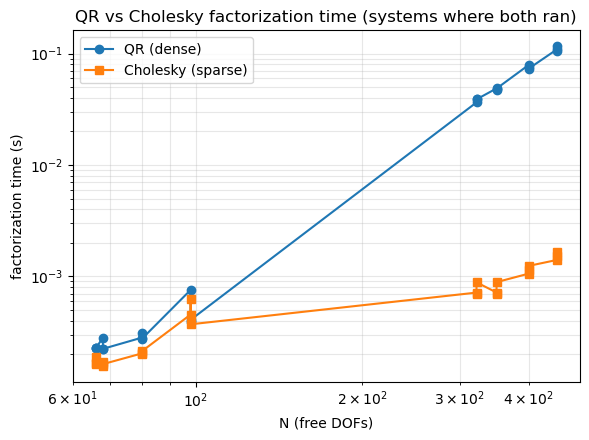

mean QR-setup / Cholesky-setup = 32.32x  (expect roughly 2x or more: the SPD penalty)


In [37]:
import scipy.linalg as sla
import matplotlib.pyplot as plt

QR_N_CAP = 1000   # dense QR only on small/medium systems (roadmap)

def qr_solve_system(sysd, repeat=3):
    """Dense QR solve Rd = Q^T f. Returns a metrics dict (or None if skipped)."""
    N = sysd["Kff"].shape[0]
    if N > QR_N_CAP:
        return None
    A = sysd["Kff"].toarray()
    Fff = sysd["Fff"]

    (Q, R), setup_t = _best_of(lambda: sla.qr(A, mode="economic"), repeat=repeat)
    d, solve_t = _best_of(lambda: sla.solve_triangular(R, Q.T @ Fff), repeat=repeat)
    rho, rel_err = solver_errors(sysd, d)
    return {
        "d": d,
        "setup_time_s": setup_t,
        "solve_time_s": solve_t,
        "residual": rho,
        "rel_error": rel_err,
    }

# Preliminary on the smallest system.
_q0 = qr_solve_system(ZOO[_mid0])
print(f"QR preliminary on {_mid0}: setup={_q0['setup_time_s']:.2e}s | solve={_q0['solve_time_s']:.2e}s | residual={_q0['residual']:.2e}")

# Full zoo (with cap).
_qr_rows = []
_qr_skipped = []
for mid, sysd in ZOO.items():
    r = qr_solve_system(sysd)
    if r is None:
        # Record a placeholder row so the table lines up; NaN total time.
        record_result(
            "qr", sysd,
            setup_time_s=np.nan,
            solve_time_s=np.nan,
            iterations=np.nan,
            final_residual=np.nan,
            rel_error=np.nan,
            tol=TOL,
            converged=True,
        )
        _qr_skipped.append((mid, sysd["Kff"].shape[0]))
        continue
    record_result(
        "qr", sysd,
        setup_time_s=r["setup_time_s"],
        solve_time_s=r["solve_time_s"],
        iterations=np.nan,
        final_residual=r["residual"],
        rel_error=r["rel_error"],
        tol=TOL,
        converged=True,
    )
    _qr_rows.append({
        "matrix_id": mid,
        "N": sysd["Kff"].shape[0],
        "setup_time_s": r["setup_time_s"],
        "solve_time_s": r["solve_time_s"],
        "residual": r["residual"],
    })

_qr_df = pd.DataFrame(_qr_rows)
print(f"QR: solved {len(_qr_df)} systems (N <= {QR_N_CAP}); skipped {len(_qr_skipped)}.")
print(_qr_df.round(6).to_string(index=False))
if _qr_skipped:
    print("QR skipped (dense, too large):")
    for mid, N in _qr_skipped:
        print(f"  {mid:30s}  N={N}")

# QR-vs-Cholesky factorization-time figure on the systems where both ran.
_chol_setup = {row["matrix_id"]: row["setup_time_s"] for row in _chol_rows}
_cmp = _qr_df.copy()
_cmp["chol_setup_time_s"] = _cmp["matrix_id"].map(_chol_setup)
_cmp = _cmp.sort_values("N")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(_cmp["N"], _cmp["setup_time_s"], "o-", label="QR (dense)")
ax.loglog(_cmp["N"], _cmp["chol_setup_time_s"], "s-", label="Cholesky (sparse)")
ax.set_xlabel("N (free DOFs)")
ax.set_ylabel("factorization time (s)")
ax.set_title("QR vs Cholesky factorization time (systems where both ran)")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

_ratio = (_cmp["setup_time_s"] / _cmp["chol_setup_time_s"]).mean()
print(f"mean QR-setup / Cholesky-setup = {_ratio:.2f}x  (expect roughly 2x or more: the SPD penalty)")


## 34b. Direct-cost study and reference check

**Objective.** (a) Confirm the reference solution `D_DIRECT` agrees with the LU/Cholesky solves at round-off, and (b) show how direct cost scales with `N` and with mesh type.

**What is done.** Three figures drawn from the direct rows already in `RESULTS`: (i) log–log `total_time_s` vs `N`, coloured by mesh `kind` (structured/distorted/unstructured), so the fill-in effect shows; (ii) a spy plot of the factor `L` for `square_structured_32` vs `square_unstructured_32`, making fill-in visible; (iii) `fill_ratio` vs `N` grouped by `kind`.

**Why it matters.** The direct baseline is what the whole comparison hangs on. These figures show where and why direct cost grows, and foreshadow the crossover with the iterative methods in Part 6B.

**Interpretation.** Direct time rises steeply with `N`; unstructured meshes are dearer at equal `N` because they fill in more; the $
u=0.49$ variant costs about the same to factor as its $
u=0.3$ twin — ill-conditioning does not touch direct cost.

**Output.** The three figures and a printed reference-agreement check.


reference check on L_structured_8: ||d_LU - d*|| / ||d*|| = 0.00e+00 (expect ~1e-15)


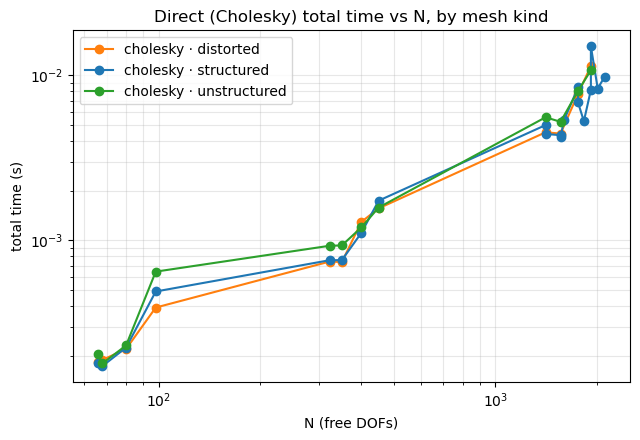

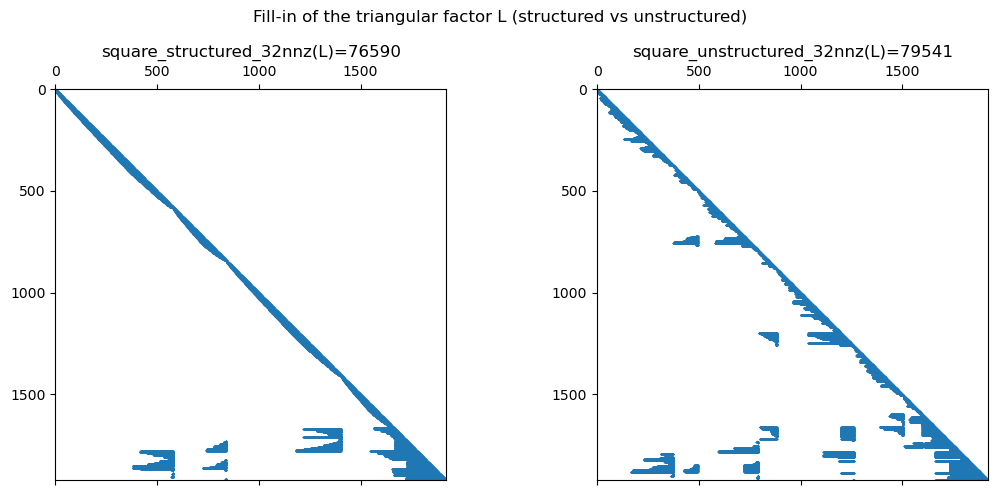

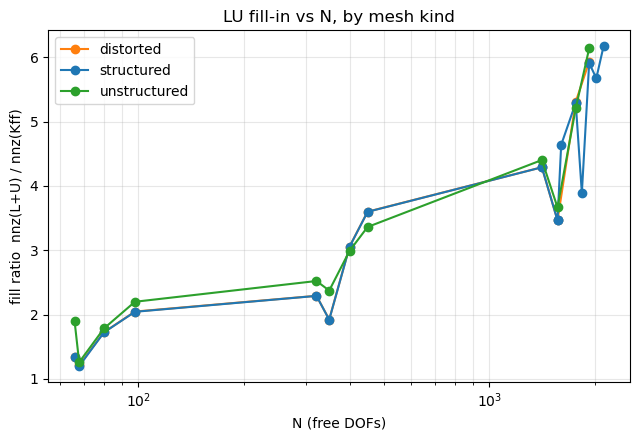

In [38]:
# (a) Reference agreement: LU/Cholesky must reproduce D_DIRECT at round-off.
_check_mid = _mid0
_dstar = D_DIRECT[_check_mid]
_lu_d = lu_solve_system(ZOO[_check_mid])["d"]
_rel = np.linalg.norm(_lu_d - _dstar) / np.linalg.norm(_dstar)
print(f"reference check on {_check_mid}: ||d_LU - d*|| / ||d*|| = {_rel:.2e} (expect ~1e-15)")

# Pull the direct rows back out of RESULTS for the scaling figures.
_direct = RESULTS[RESULTS["method"].isin(["lu", "cholesky"])].copy()

# (i) total_time_s vs N, coloured by kind.
fig, ax = plt.subplots(figsize=(6.5, 4.5))
_kind_colour = {"structured": "tab:blue", "distorted": "tab:orange", "unstructured": "tab:green"}
for kind, g in _direct[_direct["method"] == "cholesky"].groupby("kind"):
    g = g.sort_values("N")
    ax.loglog(g["N"], g["total_time_s"], "o-", color=_kind_colour.get(kind), label=f"cholesky · {kind}")
ax.set_xlabel("N (free DOFs)")
ax.set_ylabel("total time (s)")
ax.set_title("Direct (Cholesky) total time vs N, by mesh kind")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

# (ii) spy plot of the factor L: structured vs unstructured square at n=32.
def _factor_L(mid):
    Kff = ZOO[mid]["Kff"].tocsc()
    lu = spla.splu(Kff)
    return lu.L

_spy_ids = ["square_structured_32", "square_unstructured_32"]
if all(m in ZOO for m in _spy_ids):
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, mid in zip(axes, _spy_ids):
        L = _factor_L(mid)
        ax.spy(L, markersize=0.4)
        ax.set_title(f"{mid}nnz(L)={L.nnz}")
    fig.suptitle("Fill-in of the triangular factor L (structured vs unstructured)")
    plt.tight_layout()
    plt.show()
else:
    print("spy plot skipped: square_structured_32 / square_unstructured_32 not both in ZOO")

# (iii) fill_ratio vs N grouped by kind.
_fill_df = _lu_df.copy()
_fill_df["kind"] = _fill_df["matrix_id"].map(lambda m: ZOO[m]["kind"])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for kind, g in _fill_df.groupby("kind"):
    g = g.sort_values("N")
    ax.semilogx(g["N"], g["fill_ratio"], "o-", color=_kind_colour.get(kind), label=kind)
ax.set_xlabel("N (free DOFs)")
ax.set_ylabel("fill ratio  nnz(L+U) / nnz(Kff)")
ax.set_title("LU fill-in vs N, by mesh kind")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()


## 34c. Direct rows in RESULTS 

**Objective.** Show the direct baseline now sitting in `RESULTS` before the iterative methods.

**What is done.** Filter `RESULTS` to the direct methods and pivot `total_time_s` by `matrix_id` × `method`, so the LU/Cholesky/QR costs are visible side by side. Nothing is reset — Part 6B only appends.

**Interpretation.** Cholesky is the cheapest direct method in theory, LU close behind, QR visibly above both (where it ran). These are the numbers the iterative solvers must beat.

**Output.** The direct-only pivot of `total_time_s`.


In [39]:
_direct_all = RESULTS[RESULTS["method"].isin(["lu", "cholesky", "qr"])]
print(f"Direct rows in RESULTS: {len(_direct_all)} (expect ~ 2*{len(ZOO)} LU+Cholesky plus QR where it ran).")
_piv = _direct_all.pivot_table(index="matrix_id", columns="method", values="total_time_s", aggfunc="first")
print("total_time_s by matrix_id x method (direct methods):")
print(_piv.round(6).to_string())


Direct rows in RESULTS: 132 (expect ~ 2*44 LU+Cholesky plus QR where it ran).
total_time_s by matrix_id x method (direct methods):
method                       cholesky        lu        qr
matrix_id                                                
L_distorted_16               0.000743  0.001412  0.039360
L_distorted_32               0.004521  0.007300       NaN
L_distorted_8                0.000182  0.000434  0.000275
L_structured_16              0.000757  0.001394  0.036690
L_structured_32              0.005000  0.006594       NaN
L_structured_32_bottom       0.005361  0.005662       NaN
L_structured_32_nu049        0.004418  0.004810       NaN
L_structured_8               0.000180  0.000295  0.000272
L_unstructured_16            0.000927  0.001063  0.039168
L_unstructured_32            0.005575  0.006708       NaN
L_unstructured_8             0.000205  0.000501  0.000272
U_distorted_16               0.000738  0.000886  0.047416
U_distorted_32               0.004438  0.005065       NaN

# Part 6B — Iterative solvers 

Each method is implemented from scratch, analysed on the smallest system, then run across the
whole zoo and appended to `RESULTS`. All iterative methods use the same `TOL = 1e-8`.
Non-convergence (hitting the iteration cap) is recorded, not hidden.

## 35. Jacobi — preliminary on the smallest system 

**Step.** $\mathbf{x}^{k+1}=\mathbf{x}^{k}+D^{-1}(\mathbf{f}-K\mathbf{x}^{k})$, $D=\mathrm{diag}(K_{ff})$.

**Output.** Semilog residual history on the smallest system + iterations and error.

Jacobi on square_structured_8 : iters = 980 | converged = False
final residual = inf | rel error vs direct = inf


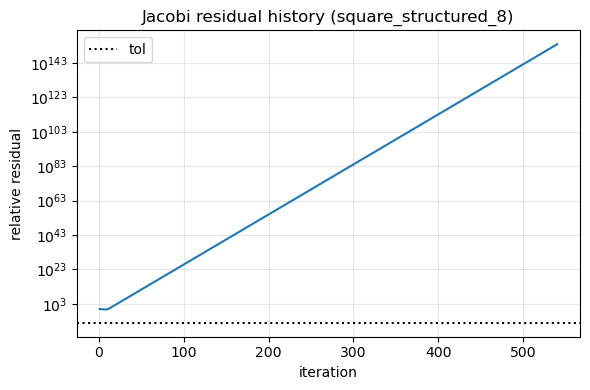

In [40]:
def jacobi(K, f, tol=TOL, maxiter=None):
    K = K.tocsr()
    n = K.shape[0]
    if maxiter is None:
        maxiter = 10 * n
    d = np.asarray(K.diagonal())
    dinv = 1.0 / d
    x = np.zeros(n)
    fnorm = np.linalg.norm(f) + 1e-30
    hist = []
    for it in range(1, maxiter + 1):
        r = f - K @ x
        rel = np.linalg.norm(r) / fnorm
        hist.append(rel)
        if rel < tol:
            return x, it, hist, True
        x = x + dinv * r
    return x, maxiter, hist, False

mid0 = 'square_structured_8'   # smallest system
s0 = ZOO[mid0]
x, it, hist, conv = jacobi(s0['Kff'], s0['Fff'])
rho, e = solver_errors(s0, x)
print("Jacobi on", mid0, ": iters =", it, "| converged =", conv)
print("final residual =", format(rho, '.2e'), "| rel error vs direct =", format(e, '.2e'))

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(range(1, len(hist) + 1), hist)
ax.axhline(TOL, color='k', ls=':', label='tol')
ax.set(xlabel='iteration', ylabel='relative residual', title='Jacobi residual history (' + mid0 + ')')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## 36. Jacobi — full zoo + first append 

**What is done.** Run Jacobi on every system, record the schema (reusing cached $\kappa$),
append to `RESULTS`, and plot iterations vs $N$ and solve time vs $N$. `converged=False`
when the cap is hit (expected on the hard matrices).

/var/folders/z4/nl4m_8q17pxg6zl3ln3klpq00000gn/T/ipykernel_22404/3568229850.py:17: RuntimeWarning: invalid value encountered in add
  x = x + dinv * r


Jacobi: converged 0 / 44 systems
                  matrix_id    N        kappa  iters   time_s  converged
              L_distorted_8   66    29.935469    660 0.009902      False
           L_unstructured_8   66    24.762920    660 0.009778      False
             L_structured_8   66    26.577945    660 0.009663      False
             U_structured_8   68    18.507098    680 0.010287      False
              U_distorted_8   68    20.554470    680 0.010096      False
           U_unstructured_8   68    15.059956    680 0.009919      False
          hole_structured_8   80    19.678651    800 0.011978      False
           hole_distorted_8   80    22.505190    800 0.013918      False
        hole_unstructured_8   80    15.637801    800 0.012070      False
      square_unstructured_8   98    33.370881    980 0.016115      False
        square_structured_8   98    42.299439    980 0.029411      False
         square_distorted_8   98    46.053658    980 0.017137      False
            L_stru

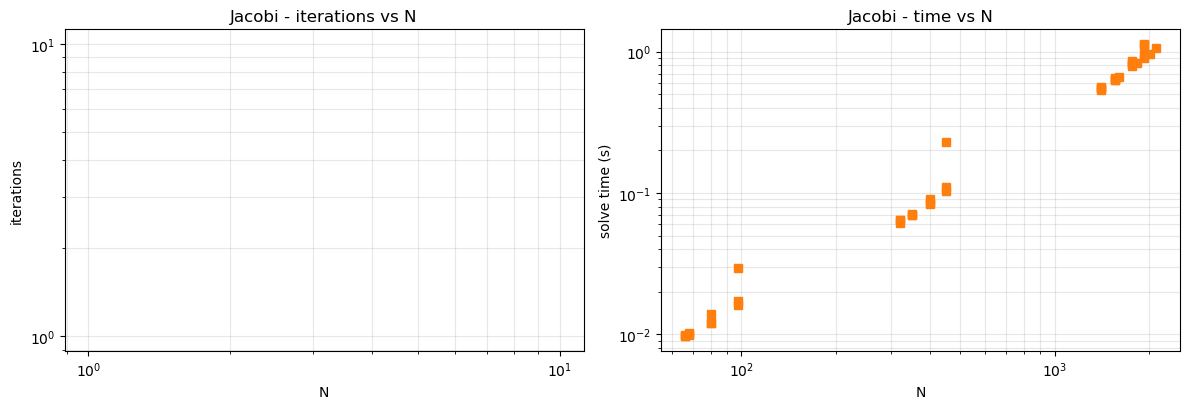

In [41]:
def run_stationary_over_zoo(method_name, solver_fn):
    rows = []
    for mid, s in ZOO.items():
        t0 = time.perf_counter()
        x, it, hist, conv = solver_fn(s['Kff'], s['Fff'])
        t_solve = time.perf_counter() - t0
        rho, e = solver_errors(s, x)
        record_result(method_name, s, setup_time_s=0.0, solve_time_s=t_solve,
                      iterations=it, final_residual=rho, rel_error=e,
                      tol=TOL, converged=conv)
        rows.append({'matrix_id': mid, 'N': s['Kff'].shape[0], 'kappa': s['kappa'],
                     'iters': it, 'time_s': t_solve, 'converged': conv})
    return pd.DataFrame(rows)

def plot_iters_time(df, title):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
    ok = df[df['converged']]
    axs[0].loglog(ok['N'], ok['iters'], 'o')
    axs[0].set(xlabel='N', ylabel='iterations', title=title + ' - iterations vs N')
    axs[0].grid(True, which='both', alpha=0.3)
    axs[1].loglog(df['N'], df['time_s'], 's', color='tab:orange')
    axs[1].set(xlabel='N', ylabel='solve time (s)', title=title + ' - time vs N')
    axs[1].grid(True, which='both', alpha=0.3)
    plt.tight_layout(); plt.show()

jac_df = run_stationary_over_zoo('jacobi', jacobi)
print("Jacobi: converged", int(jac_df['converged'].sum()), "/", len(jac_df), "systems")
print(jac_df.sort_values('N').to_string(index=False))
plot_iters_time(jac_df, 'Jacobi')

## 37-38. Gauss–Seidel — preliminary and full zoo 

**Step.** $(D+L)\mathbf{x}^{k+1}=\mathbf{f}-U\mathbf{x}^{k}$ (forward sweep with updated
components). Implemented with a sparse-triangular solve per sweep. Expected ~2× fewer
iterations than Jacobi.

Gauss-Seidel on square_structured_8 : iters = 136 | residual = 8.90e-09 | error = 8.98e-09


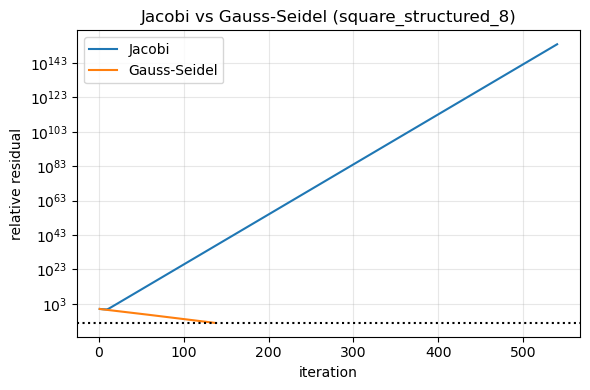

Gauss-Seidel: converged 36 / 44 systems


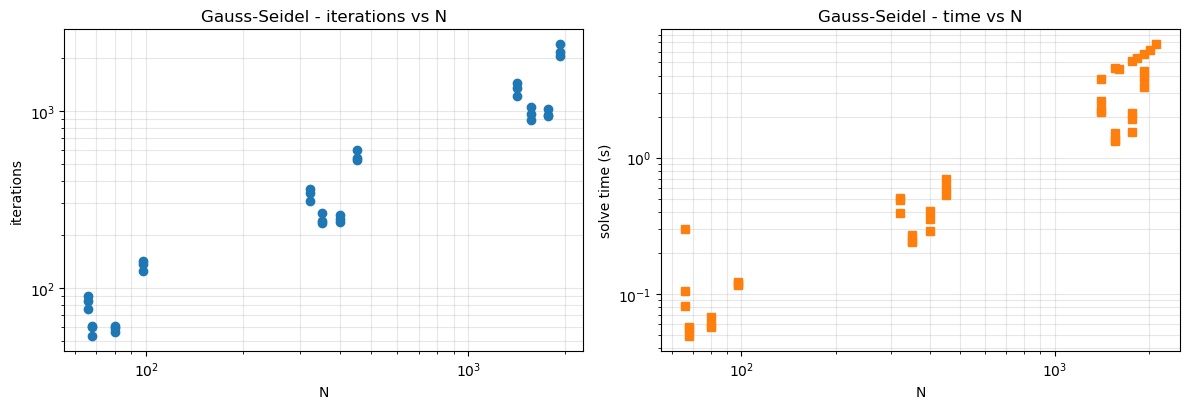

In [42]:
def gauss_seidel(K, f, tol=TOL, maxiter=None):
    K = K.tocsr()
    n = K.shape[0]
    if maxiter is None:
        maxiter = 2 * n
    DL = sp.tril(K, k=0).tocsr()       # D + L (lower triangular, incl. diagonal)
    U = sp.triu(K, k=1).tocsr()        # strict upper
    x = np.zeros(n)
    fnorm = np.linalg.norm(f) + 1e-30
    hist = []
    for it in range(1, maxiter + 1):
        rel = np.linalg.norm(f - K @ x) / fnorm
        hist.append(rel)
        if rel < tol:
            return x, it, hist, True
        x = spla.spsolve_triangular(DL, f - U @ x, lower=True)
    return x, maxiter, hist, False

# preliminary overlay vs Jacobi on the smallest system
xg, itg, histg, convg = gauss_seidel(s0['Kff'], s0['Fff'])
rhog, eg = solver_errors(s0, xg)
print("Gauss-Seidel on", mid0, ": iters =", itg, "| residual =", format(rhog, '.2e'), "| error =", format(eg, '.2e'))

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(range(1, len(hist) + 1), hist, label='Jacobi')
ax.semilogy(range(1, len(histg) + 1), histg, label='Gauss-Seidel')
ax.axhline(TOL, color='k', ls=':')
ax.set(xlabel='iteration', ylabel='relative residual', title='Jacobi vs Gauss-Seidel (' + mid0 + ')')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

gs_df = run_stationary_over_zoo('gs', gauss_seidel)
print("Gauss-Seidel: converged", int(gs_df['converged'].sum()), "/", len(gs_df), "systems")
plot_iters_time(gs_df, 'Gauss-Seidel')

## 39-40. Conjugate Gradient — preliminary and full zoo 

**Step.** SPD Krylov: $K$-conjugate directions, step
$\alpha_k=(\mathbf{r}_k^\top\mathbf{r}_k)/(\mathbf{p}_k^\top K\mathbf{p}_k)$. Implemented
from scratch; one sparse mat-vec per iteration. Theory: iterations grow like
$\mathcal{O}(\sqrt{\kappa})$. The iterations-vs-N plot overlays a $\sqrt{\kappa}$ guide.

CG on square_structured_8 : iters = 33 | residual = 6.19e-09 | error = 7.55e-10


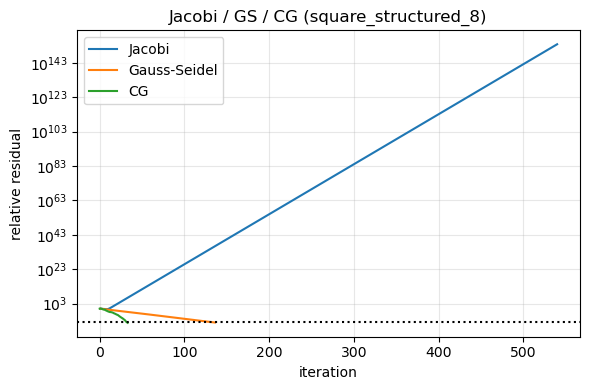

CG: converged 44 / 44 systems


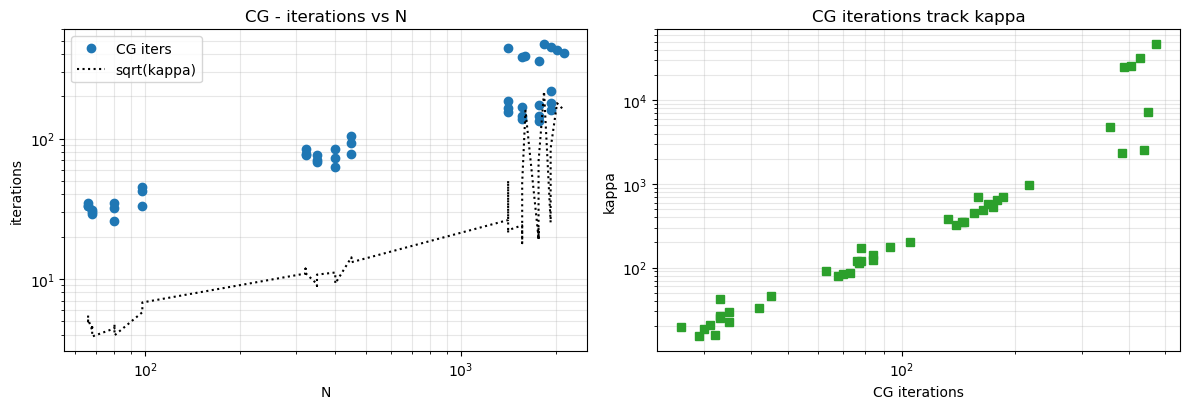

In [43]:
def cg(K, f, tol=TOL, maxiter=None):
    K = K.tocsr()
    n = K.shape[0]
    if maxiter is None:
        maxiter = 2 * n
    x = np.zeros(n)
    r = f - K @ x
    p = r.copy()
    rs_old = r @ r
    fnorm = np.linalg.norm(f) + 1e-30
    hist = [np.sqrt(rs_old) / fnorm]
    if hist[-1] < tol:
        return x, 0, hist, True
    for it in range(1, maxiter + 1):
        Kp = K @ p
        alpha = rs_old / (p @ Kp)
        x = x + alpha * p
        r = r - alpha * Kp
        rs_new = r @ r
        rel = np.sqrt(rs_new) / fnorm
        hist.append(rel)
        if rel < tol:
            return x, it, hist, True
        p = r + (rs_new / rs_old) * p
        rs_old = rs_new
    return x, maxiter, hist, False

# preliminary overlay: CG vs GS vs Jacobi on the smallest system
xc, itc, histc, convc = cg(s0['Kff'], s0['Fff'])
rhoc, ec = solver_errors(s0, xc)
print("CG on", mid0, ": iters =", itc, "| residual =", format(rhoc, '.2e'), "| error =", format(ec, '.2e'))

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(range(1, len(hist) + 1), hist, label='Jacobi')
ax.semilogy(range(1, len(histg) + 1), histg, label='Gauss-Seidel')
ax.semilogy(range(len(histc)), histc, label='CG')
ax.axhline(TOL, color='k', ls=':')
ax.set(xlabel='iteration', ylabel='relative residual', title='Jacobi / GS / CG (' + mid0 + ')')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

# full zoo
cg_rows = []
for mid, s in ZOO.items():
    t0 = time.perf_counter()
    x, it, histx, conv = cg(s['Kff'], s['Fff'])
    t_solve = time.perf_counter() - t0
    rho, e = solver_errors(s, x)
    record_result('cg', s, setup_time_s=0.0, solve_time_s=t_solve,
                  iterations=it, final_residual=rho, rel_error=e, tol=TOL, converged=conv)
    cg_rows.append({'matrix_id': mid, 'N': s['Kff'].shape[0], 'kappa': s['kappa'],
                    'iters': it, 'time_s': t_solve, 'converged': conv})
cg_df = pd.DataFrame(cg_rows)
print("CG: converged", int(cg_df['converged'].sum()), "/", len(cg_df), "systems")

# iterations vs N with sqrt(kappa) guide
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].loglog(cg_df['N'], cg_df['iters'], 'o', label='CG iters')
order = cg_df.sort_values('N')
axs[0].loglog(order['N'], np.sqrt(order['kappa']), 'k:', label='sqrt(kappa)')
axs[0].set(xlabel='N', ylabel='iterations', title='CG - iterations vs N')
axs[0].legend(); axs[0].grid(True, which='both', alpha=0.3)
axs[1].loglog(cg_df['iters'], cg_df['kappa'], 's', color='tab:green')
axs[1].set(xlabel='CG iterations', ylabel='kappa', title='CG iterations track kappa')
axs[1].grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## 41. MINRES — full zoo 

**Step.** Symmetric Krylov via Lanczos, minimising the residual 2-norm. Uses
`scipy.sparse.linalg.minres` with an iteration callback. On SPD, CG minimises the error
$A$-norm and MINRES the residual 2-norm, so their counts are close but not identical; CG is
usually preferred (shorter recurrence).

MINRES: converged 44 / 44 systems


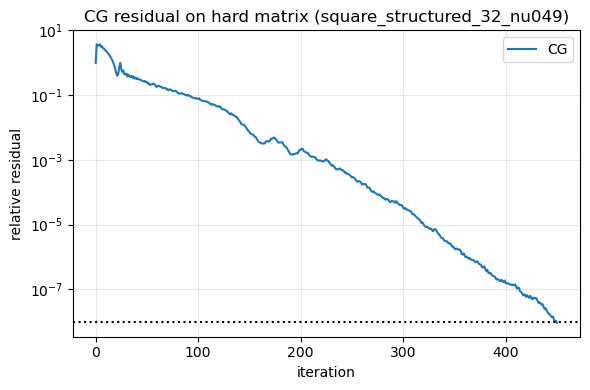

In [44]:
def minres_solve(K, f, tol=TOL, maxiter=None):
    K = K.tocsr()
    n = K.shape[0]
    if maxiter is None:
        maxiter = 2 * n
    count = {'it': 0}
    def cb(xk):
        count['it'] += 1
    x, info = spla.minres(K, f, rtol=tol, maxiter=maxiter, callback=cb)
    conv = (info == 0)
    return x, count['it'], conv

mr_rows = []
for mid, s in ZOO.items():
    t0 = time.perf_counter()
    try:
        x, it, conv = minres_solve(s['Kff'], s['Fff'])
    except TypeError:
        # older SciPy: 'rtol' was called 'tol'
        K = s['Kff'].tocsr(); count = {'it': 0}
        def cb(xk, count=count): count['it'] += 1
        x, info = spla.minres(K, s['Fff'], tol=TOL, maxiter=2 * K.shape[0], callback=cb)
        it, conv = count['it'], (info == 0)
    t_solve = time.perf_counter() - t0
    rho, e = solver_errors(s, x)
    record_result('minres', s, setup_time_s=0.0, solve_time_s=t_solve,
                  iterations=it, final_residual=rho, rel_error=e, tol=TOL, converged=conv)
    mr_rows.append({'matrix_id': mid, 'N': s['Kff'].shape[0], 'iters': it,
                    'time_s': t_solve, 'converged': conv})
mr_df = pd.DataFrame(mr_rows)
print("MINRES: converged", int(mr_df['converged'].sum()), "/", len(mr_df), "systems")

# CG vs MINRES residual history on a hard matrix
hard = 'square_structured_32_nu049'
sh = ZOO[hard]
_, _, histc2, _ = cg(sh['Kff'], sh['Fff'])
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(range(len(histc2)), histc2, label='CG')
ax.axhline(TOL, color='k', ls=':')
ax.set(xlabel='iteration', ylabel='relative residual', title='CG residual on hard matrix (' + hard + ')')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## 42. PCG with incomplete-Cholesky preconditioner 

**Step.** CG with $M\approx K_{ff}$ from an incomplete factorization. SciPy has no incomplete
Cholesky, so we use `spilu` (incomplete LU) on the SPD matrix as an IC(0)-style stand-in and
wrap it as a `LinearOperator`. We record **setup time** (building the preconditioner)
separately — it is nonzero, unlike plain CG. Expected: large iteration drop on the fine and
near-incompressible systems.

PCG-IC on square_structured_32_nu049 : iters = 3844 | setup = 0.015 s | residual = 1.98e+00
(plain CG on same matrix took 450 iters)
PCG-IC: converged 30 / 44 systems


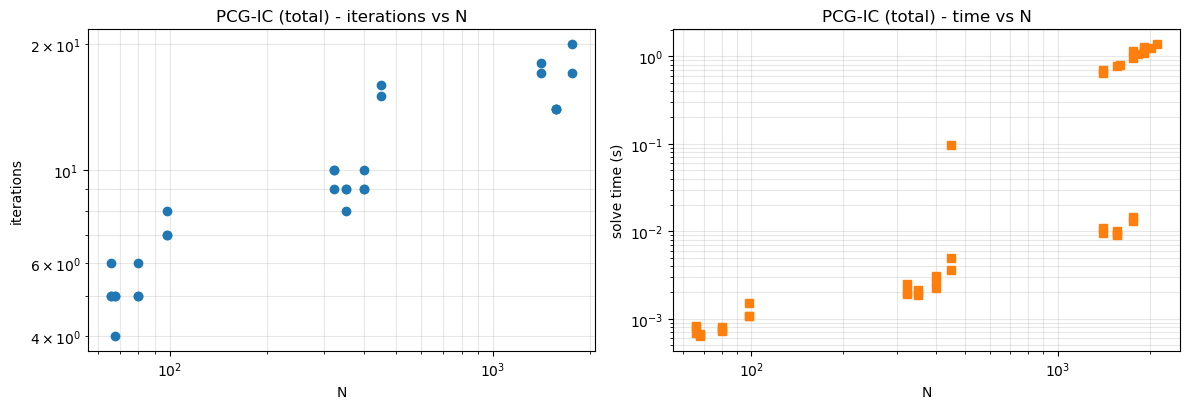

In [45]:
def pcg_ic(K, f, tol=TOL, maxiter=None, drop_tol=1e-2, fill_factor=2):
    K = K.tocsc()
    n = K.shape[0]
    if maxiter is None:
        maxiter = 2 * n
    t0 = time.perf_counter()
    ilu = spla.spilu(K, drop_tol=drop_tol, fill_factor=fill_factor)
    M = spla.LinearOperator((n, n), matvec=ilu.solve)
    t_setup = time.perf_counter() - t0
    count = {'it': 0}
    def cb(xk):
        count['it'] += 1
    t1 = time.perf_counter()
    try:
        x, info = spla.cg(K, f, rtol=tol, maxiter=maxiter, M=M, callback=cb)
    except TypeError:
        x, info = spla.cg(K, f, tol=tol, maxiter=maxiter, M=M, callback=cb)
    t_solve = time.perf_counter() - t1
    return x, count['it'], (info == 0), t_setup, t_solve

# preliminary overlay vs plain CG on the hard matrix
xp, itp, convp, t_set, t_sol = pcg_ic(sh['Kff'], sh['Fff'])
rhop, ep = solver_errors(sh, xp)
print("PCG-IC on", hard, ": iters =", itp, "| setup =", format(t_set, '.3f'), "s | residual =", format(rhop, '.2e'))
print("(plain CG on same matrix took", len(histc2) - 1, "iters)")

pc_rows = []
for mid, s in ZOO.items():
    x, it, conv, t_set, t_sol = pcg_ic(s['Kff'], s['Fff'])
    rho, e = solver_errors(s, x)
    record_result('pcg_ic', s, setup_time_s=t_set, solve_time_s=t_sol,
                  iterations=it, final_residual=rho, rel_error=e, tol=TOL, converged=conv)
    pc_rows.append({'matrix_id': mid, 'N': s['Kff'].shape[0], 'kappa': s['kappa'],
                    'iters': it, 'setup_s': t_set, 'solve_s': t_sol, 'converged': conv})
pc_df = pd.DataFrame(pc_rows)
print("PCG-IC: converged", int(pc_df['converged'].sum()), "/", len(pc_df), "systems")
plot_iters_time(pc_df.assign(time_s=pc_df['setup_s'] + pc_df['solve_s']), 'PCG-IC (total)')

## Large Matrix Experiments

In [46]:
"""## 42b. Large-scale systems (n=64, n=128) — the crossover experiment

**Objective.** Add two much larger square-structured systems so Section 44's figures can show
where (if anywhere) the iterative methods overtake the direct ones. These are appended to `ZOO`,
`D_DIRECT` and `RESULTS` with all columns computed, exactly like the 44 zoo systems — only four
solvers are run (Cholesky, LU, CG, PCG-IC). QR (dense) and the stationary methods are skipped:
QR would need an 8 GB dense array at n=128, and Jacobi diverges on elasticity.

**Output.** The two matrix sizes (rows × columns) and a mini pivot of total time per method.
"""

# --- build the two large systems and register them in ZOO (so groupbys see them) ---
_LARGE_LEVELS = [64, 128]
for _lvl in _LARGE_LEVELS:
    _mid = 'square_structured_' + str(_lvl)
    if _mid in ZOO:
        continue                       # already present; don't duplicate
    _s = build_suite('square', 'structured', _lvl)
    _sysd = system_from_suite(_s, bc_mode='all', model='plane_strain')
    _sysd['matrix_id'] = _mid
    _sysd['shape'] = 'square'; _sysd['kind'] = 'structured'
    _sysd['level'] = _lvl; _sysd['bc'] = 'all'; _sysd['nu'] = NU
    ZOO[_mid] = _sysd

# --- for each new system: properties (symmetric/spd/kappa), direct reference, then 4 solvers ---
_LARGE_IDS = ['square_structured_' + str(l) for l in _LARGE_LEVELS]
for _mid in _LARGE_IDS:
    s = ZOO[_mid]
    Kff = s['Kff']
    N = Kff.shape[0]
    print("")
    print("=== " + _mid + " : matrix size = " + str(N) + " x " + str(N) + ", nnz = " + str(Kff.nnz) + " ===")

    # properties (Section 30 work, for just this system)
    s['symmetric'] = bool(spla.norm(Kff - Kff.T) / spla.norm(Kff) < 1e-10)
    print("computing condition number (eigsh; slow for n=128)...")
    s['kappa'] = cond_number(Kff)
    _lmin = spla.eigsh(Kff.tocsc(), k=1, sigma=0, which='LM', return_eigenvectors=False)[0]
    s['spd'] = bool(_lmin > 0)
    print("  symmetric =", s['symmetric'], "| spd =", s['spd'], "| kappa =", format(s['kappa'], '.1f'))

    # direct reference solution (accuracy oracle) so solver_errors works for this matrix_id
    D_DIRECT[_mid] = spla.spsolve(Kff, s['Fff'])

    # Cholesky
    r = cholesky_solve_system(s)
    record_result('cholesky', s, setup_time_s=r['setup_time_s'], solve_time_s=r['solve_time_s'],
                  iterations=np.nan, final_residual=r['residual'], rel_error=r['rel_error'],
                  tol=TOL, converged=True)
    print("  cholesky: total =", format(r['setup_time_s'] + r['solve_time_s'], '.4f'), "s")

    # LU
    r = lu_solve_system(s)
    record_result('lu', s, setup_time_s=r['setup_time_s'], solve_time_s=r['solve_time_s'],
                  iterations=np.nan, final_residual=r['residual'], rel_error=r['rel_error'],
                  tol=TOL, converged=True)
    print("  lu      : total =", format(r['setup_time_s'] + r['solve_time_s'], '.4f'), "s")

    # CG
    t0 = time.perf_counter()
    x, it, _h, conv = cg(s['Kff'], s['Fff'])
    t_cg = time.perf_counter() - t0
    rho, e = solver_errors(s, x)
    record_result('cg', s, setup_time_s=0.0, solve_time_s=t_cg,
                  iterations=it, final_residual=rho, rel_error=e, tol=TOL, converged=conv)
    print("  cg      : total =", format(t_cg, '.4f'), "s | iters =", it, "| converged =", conv)

    # PCG-IC
    x, it, conv, t_set, t_sol = pcg_ic(s['Kff'], s['Fff'])
    rho, e = solver_errors(s, x)
    record_result('pcg_ic', s, setup_time_s=t_set, solve_time_s=t_sol,
                  iterations=it, final_residual=rho, rel_error=e, tol=TOL, converged=conv)
    print("  pcg_ic  : total =", format(t_set + t_sol, '.4f'), "s | iters =", it, "| converged =", conv)

# --- mini pivot to verify the new rows landed ---
_new = RESULTS[RESULTS['matrix_id'].isin(_LARGE_IDS)]
print("")
print("new large-system rows in RESULTS:", len(_new))
print(_new.pivot_table(index='matrix_id', columns='method',
                       values='total_time_s', aggfunc='first').round(4).to_string())



=== square_structured_64 : matrix size = 7938 x 7938, nnz = 109124 ===
computing condition number (eigsh; slow for n=128)...
  symmetric = True | spd = True | kappa = 2781.7
  cholesky: total = 0.0733 s
  lu      : total = 0.0716 s
  cg      : total = 0.0599 s | iters = 317 | converged = True
  pcg_ic  : total = 19.7543 s | iters = 15876 | converged = False

=== square_structured_128 : matrix size = 32258 x 32258, nnz = 447556 ===
computing condition number (eigsh; slow for n=128)...
  symmetric = True | spd = True | kappa = 11130.4
  cholesky: total = 0.7481 s
  lu      : total = 0.7097 s
  cg      : total = 0.5027 s | iters = 622 | converged = True
  pcg_ic  : total = 359.2290 s | iters = 64516 | converged = False

new large-system rows in RESULTS: 8
method                     cg  cholesky      lu    pcg_ic
matrix_id                                                
square_structured_128  0.5027    0.7481  0.7097  359.2290
square_structured_64   0.0599    0.0733  0.0716   19.7543


## 43. Snapshot of `RESULTS` + pivots 

**Output.** The accumulated table and pivots of iterations and total time
(rows = `matrix_id`, columns = `method`), plus a `converged` pivot.

In [47]:
print("RESULTS so far:", len(RESULTS), "rows | methods:", sorted(RESULTS['method'].unique()))
print("")
piv_it = RESULTS.pivot_table(index='matrix_id', columns='method', values='iterations')
print("ITERATIONS (rows=matrix, cols=method):")
print(piv_it.to_string())
print("")
piv_t = RESULTS.pivot_table(index='matrix_id', columns='method', values='total_time_s')
print("TOTAL TIME s (rows=matrix, cols=method):")
print(piv_t.round(4).to_string())
print("")
piv_c = RESULTS.pivot_table(index='matrix_id', columns='method', values='converged', aggfunc='first')
print("CONVERGED:")
print(piv_c.to_string())

RESULTS so far: 360 rows | methods: ['cg', 'cholesky', 'gs', 'jacobi', 'lu', 'minres', 'pcg_ic', 'qr']

ITERATIONS (rows=matrix, cols=method):
method                          cg      gs   jacobi  minres   pcg_ic
matrix_id                                                           
L_distorted_16                84.0   346.0   3220.0    62.0     10.0
L_distorted_32               186.0  1352.0  14100.0   118.0     18.0
L_distorted_8                 35.0    84.0    660.0    30.0      5.0
L_structured_16               78.0   309.0   3220.0    57.0      9.0
L_structured_32              164.0  1225.0  14100.0   106.0     17.0
L_structured_32_bottom       388.0  3200.0  16000.0   280.0   3200.0
L_structured_32_nu049        440.0  2820.0  14100.0   214.0   2820.0
L_structured_8                33.0    76.0    660.0    28.0      5.0
L_unstructured_16             76.0   363.0   3220.0    57.0     10.0
L_unstructured_32            156.0  1451.0  14100.0   103.0   2820.0
L_unstructured_8             

# Section 44 — Overall comparison

This section merges direct
and iterative on the same figures and **computes `speedup_vs_direct`** (which `record_result` left as
`NaN`). All figures read only from `RESULTS` (+ cached `kappa`). One shared colour map so a method is
the same colour in every plot.

## 44.0 — Fill in `speedup_vs_direct`

**Objective.** The benchmark comparison the roadmap asks for. For every row, set
`speedup_vs_direct = total_time(Cholesky, same matrix) / total_time(this method)`. Values > 1 mean
the method is *faster* than the Cholesky direct reference on that matrix; < 1 means slower. Cholesky
itself is 1.0 by definition. Non-converged or untimed rows stay `NaN`.

In [48]:
# reference time per matrix = Cholesky total_time_s
_chol_time = (RESULTS[RESULTS['method'] == 'cholesky']
              .dropna(subset=['total_time_s'])
              .set_index('matrix_id')['total_time_s'].to_dict())

def _speedup(row):
    ref = _chol_time.get(row['matrix_id'], np.nan)
    t = row['total_time_s']
    if ref != ref or t != t or t == 0:   # NaN guard
        return np.nan
    if row['converged'] == False:
        return np.nan                    # a non-converged run has no meaningful speedup
    return ref / t

RESULTS['speedup_vs_direct'] = RESULTS.apply(_speedup, axis=1)
print("speedup_vs_direct filled. non-null rows:", int(RESULTS['speedup_vs_direct'].notna().sum()))
print("")
print("median speedup vs Cholesky, by method (converged rows):")
print(RESULTS[RESULTS['converged'] == True].groupby('method')['speedup_vs_direct'].median().round(3).to_string())

speedup_vs_direct filled. non-null rows: 272

median speedup vs Cholesky, by method (converged rows):
method
cg          0.394
cholesky    1.000
gs          0.003
lu          0.855
minres      0.164
pcg_ic      0.391
qr          0.277


In [49]:
# RESULTS was row-appended via pd.concat, which can leave numeric columns as object.
# Coerce them once so plotting / groupby / pivots behave.
_num_cols = ['level', 'nu', 'N', 'nnz', 'kappa',
             'setup_time_s', 'solve_time_s', 'total_time_s',
             'iterations', 'tol', 'final_residual', 'rel_error', 'speedup_vs_direct']
for _c in _num_cols:
    RESULTS[_c] = pd.to_numeric(RESULTS[_c], errors='coerce')
RESULTS['converged'] = RESULTS['converged'].astype(bool)

print("dtypes after coercion:")
print(RESULTS[_num_cols + ['converged']].dtypes)


dtypes after coercion:
level                  int64
nu                   float64
N                      int64
nnz                    int64
kappa                float64
setup_time_s         float64
solve_time_s         float64
total_time_s         float64
iterations           float64
tol                  float64
final_residual       float64
rel_error            float64
speedup_vs_direct    float64
converged               bool
dtype: object


## 44a — Total time vs N, all methods on one log–log plot

The headline figure: direct and iterative on the **same axes**, so the crossover is visible. Left:
`square, structured` only (clean refinement slopes). Right: every system.

In [50]:
# shared colour map for all 8 methods (direct + iterative)
ALL_METHODS = ['lu', 'cholesky', 'qr', 'jacobi', 'gs', 'cg', 'minres', 'pcg_ic']
_pal = plt.cm.tab10(np.linspace(0, 1, 10))
METHOD_COLOR = {m: _pal[i] for i, m in enumerate(ALL_METHODS)}
DIRECT = ['lu', 'cholesky', 'qr']
ITER = ['jacobi', 'gs', 'cg', 'minres', 'pcg_ic']

# RESULTS was row-appended via pd.concat, so coerce numeric columns once
for _c in ['level','nu','N','nnz','kappa','setup_time_s','solve_time_s',
           'total_time_s','iterations','tol','final_residual','rel_error','speedup_vs_direct']:
    RESULTS[_c] = pd.to_numeric(RESULTS[_c], errors='coerce')
RESULTS['converged'] = RESULTS['converged'].astype(bool)

print("ALL_METHODS defined:", ALL_METHODS)
print("N dtype now:", RESULTS['N'].dtype)

ALL_METHODS defined: ['lu', 'cholesky', 'qr', 'jacobi', 'gs', 'cg', 'minres', 'pcg_ic']
N dtype now: int64


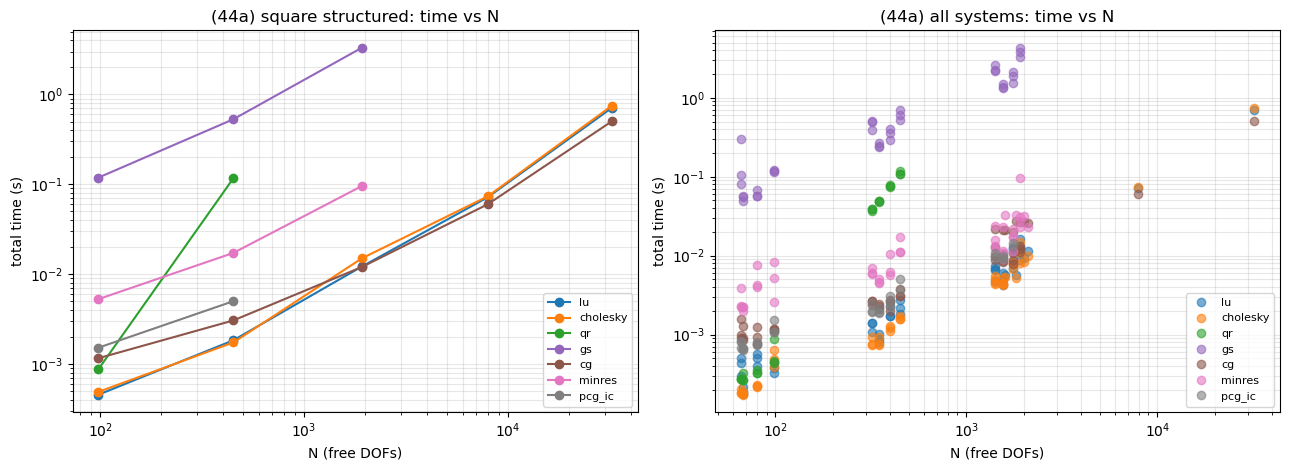

In [51]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))

sub = RESULTS[(RESULTS['shape'] == 'square') & (RESULTS['kind'] == 'structured') & (RESULTS['bc'] == 'all') & (RESULTS['nu'] == 0.3)]
for m in ALL_METHODS:
    g = sub[(sub['method'] == m) & (sub['converged'] == True)].dropna(subset=['total_time_s']).sort_values('N')
    if len(g):
        axs[0].loglog(g['N'], g['total_time_s'], 'o-', color=METHOD_COLOR[m], label=m)
axs[0].set(xlabel='N (free DOFs)', ylabel='total time (s)', title='(44a) square structured: time vs N')
axs[0].legend(fontsize=8); axs[0].grid(True, which='both', alpha=0.3)

for m in ALL_METHODS:
    g = RESULTS[(RESULTS['method'] == m) & (RESULTS['converged'] == True)].dropna(subset=['total_time_s'])
    if len(g):
        axs[1].loglog(g['N'], g['total_time_s'], 'o', color=METHOD_COLOR[m], label=m, alpha=0.6)
axs[1].set(xlabel='N (free DOFs)', ylabel='total time (s)', title='(44a) all systems: time vs N')
axs[1].legend(fontsize=8); axs[1].grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## 44b — Iterations vs κ

The zoo spans a wide range of $\kappa$ at similar $N$, so iterations-vs-$\kappa$ isolates conditioning
as the real driver. CG tracks $\sqrt{\kappa}$; PCG-IC is almost flat; Jacobi/GS (where they converge)
sit far above.

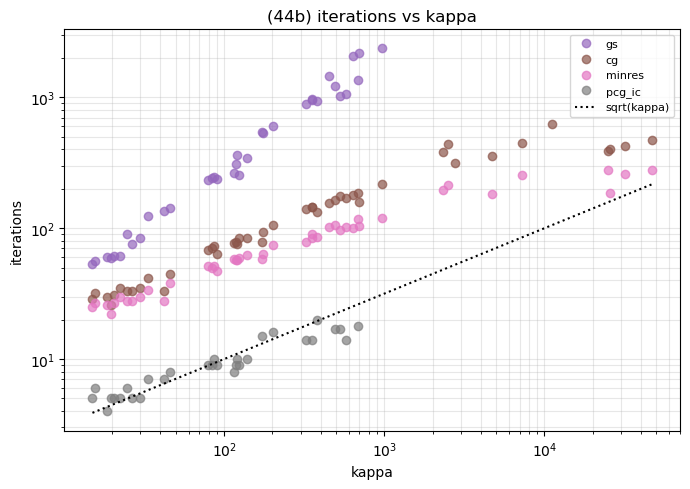

In [52]:
fig, ax = plt.subplots(figsize=(7, 5))
for m in ITER:
    g = RESULTS[(RESULTS['method'] == m) & (RESULTS['converged'] == True)].dropna(subset=['kappa', 'iterations'])
    if len(g):
        ax.loglog(g['kappa'], g['iterations'], 'o', color=METHOD_COLOR[m], label=m, alpha=0.7)
kk = np.array(sorted(RESULTS['kappa'].dropna().unique()))
if len(kk):
    ax.loglog(kk, np.sqrt(kk), 'k:', label='sqrt(kappa)')
ax.set(xlabel='kappa', ylabel='iterations', title='(44b) iterations vs kappa')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## 44c — Accuracy vs cost (direct + iterative)

Relative error against the direct reference vs total time, one point per (method, matrix). Direct
methods are accurate but to the right (slower); CG/PCG cluster near direct accuracy at lower cost;
non-converged Jacobi/GS appear as high-error outliers.

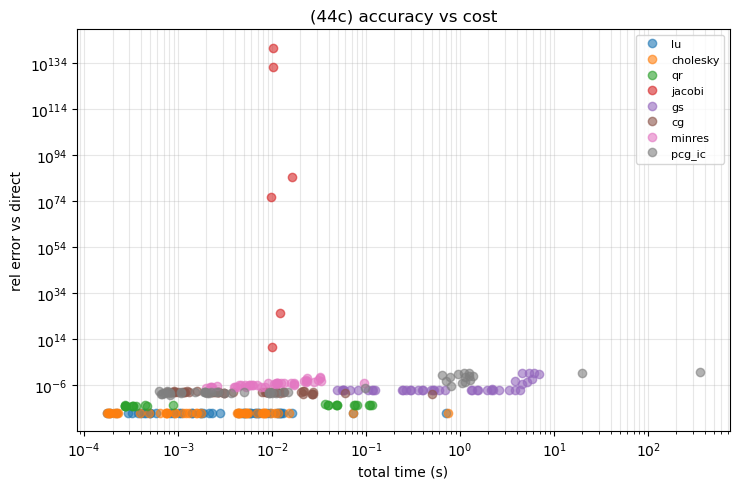

In [53]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for m in ALL_METHODS:
    g = RESULTS[RESULTS['method'] == m].dropna(subset=['total_time_s', 'rel_error'])
    if len(g):
        ax.loglog(g['total_time_s'] + 1e-6, g['rel_error'] + 1e-18, 'o',
                  color=METHOD_COLOR[m], label=m, alpha=0.6)
ax.set(xlabel='total time (s)', ylabel='rel error vs direct', title='(44c) accuracy vs cost')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## 44d — Effect of each zoo axis on iterative cost

Mean iterations (converged runs) grouped by each experimental axis — `level`, `kind`, `shape`, `bc`,
`nu`. Directly answers the brief: *how geometry, loads, supports and material affect solver
performance.*

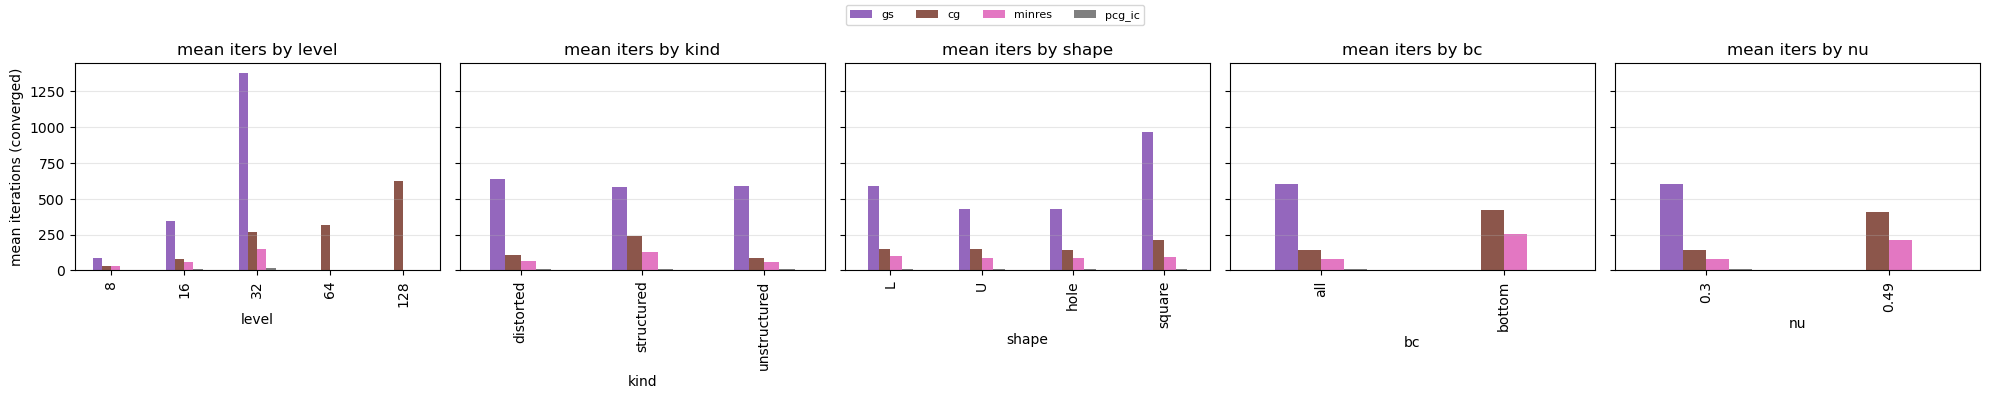

In [54]:
conv = RESULTS[(RESULTS['converged'] == True) & RESULTS['iterations'].notna()]
axes_to_plot = ['level', 'kind', 'shape', 'bc', 'nu']
fig, axs = plt.subplots(1, len(axes_to_plot), figsize=(4 * len(axes_to_plot), 4), sharey=True)
for ax, axis in zip(axs, axes_to_plot):
    piv = conv.pivot_table(index=axis, columns='method', values='iterations', aggfunc='mean')
    piv = piv.reindex(columns=[m for m in ITER if m in piv.columns])
    piv.plot(kind='bar', ax=ax, color=[METHOD_COLOR[m] for m in piv.columns], legend=False)
    ax.set_title('mean iters by ' + axis); ax.set_xlabel(axis); ax.grid(True, axis='y', alpha=0.3)
axs[0].set_ylabel('mean iterations (converged)')
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', ncol=len(l), fontsize=8)
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

## 44e — Speedup vs Cholesky (heatmap)

`speedup_vs_direct` on a representative slice of the zoo. Green = faster than Cholesky, red = slower.
This is the explicit benchmark-vs-direct comparison.

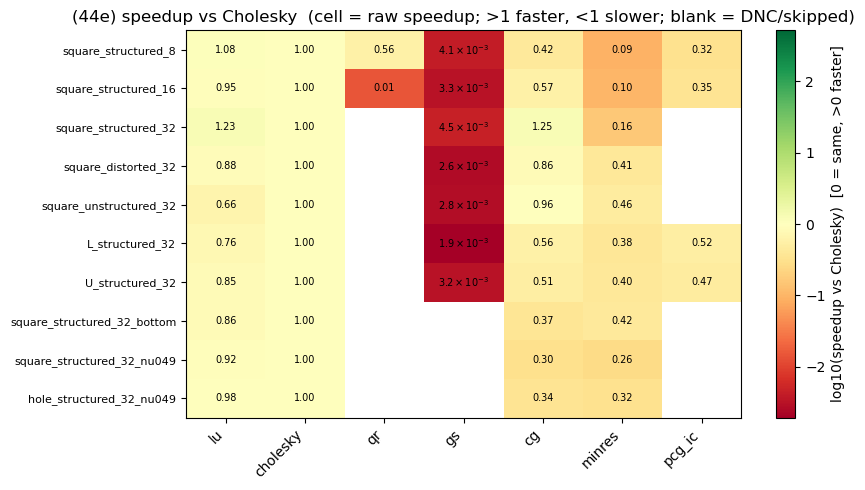

In [55]:
# =====================================================================
# 44e. Speedup vs Cholesky (heatmap)
# =====================================================================
rep = ['square_structured_8', 'square_structured_16', 'square_structured_32',
       'square_distorted_32', 'square_unstructured_32', 'L_structured_32', 'U_structured_32',
       'square_structured_32_bottom', 'square_structured_32_nu049', 'hole_structured_32_nu049']
rep = [m for m in rep if m in set(RESULTS['matrix_id'])]

heat = (RESULTS[RESULTS['matrix_id'].isin(rep)]
        .pivot_table(index='matrix_id', columns='method', values='speedup_vs_direct', aggfunc='first')
        .reindex(index=rep, columns=[m for m in ALL_METHODS]))

# drop columns that are entirely NaN (e.g. jacobi, which never converged)
heat = heat.dropna(axis=1, how='all')

def fmt_speedup(v):
    """Readable cell label: plain decimals in the mid-range [1e-2, 1e3),
    scientific 'a x 10^b' outside it (so tiny GS values show, not '0.0')."""
    if v != v:            # NaN
        return ""
    if v == 0:
        return "0"
    av = abs(v)
    if 1e-2 <= av < 1e3:                       # mid-range: plain decimals
        return format(v, '.2f') if av < 10 else format(v, '.0f')
    exp = int(np.floor(np.log10(av)))          # scientific: mantissa x 10^exp
    mant = v / (10 ** exp)
    return r"$%.1f\times10^{%d}$" % (mant, exp)

fig, ax = plt.subplots(figsize=(9, 5))
data = heat.values.astype(float)

# colour: log10(speedup), symmetric about 0 (= 1x = same as Cholesky)
logdata = np.log10(np.where(data > 0, data, np.nan))
vmax = np.nanmax(np.abs(logdata))
vmax = vmax if (vmax == vmax and vmax > 0) else 1.0
im = ax.imshow(logdata, aspect='auto', cmap='RdYlGn', vmin=-vmax, vmax=vmax)

ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(heat.columns, rotation=45, ha='right')
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index, fontsize=8)

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        val = data[i, j]
        if val == val:    # not NaN
            ax.text(j, i, fmt_speedup(val), ha='center', va='center', fontsize=7)

fig.colorbar(im, ax=ax, label='log10(speedup vs Cholesky)  [0 = same, >0 faster]')
ax.set_title('(44e) speedup vs Cholesky  (cell = raw speedup; >1 faster, <1 slower; blank = DNC/skipped)')
plt.tight_layout(); plt.show()



## 44f — Residual vs error plateau (tolerance sweep)

On one well-conditioned and one ill-conditioned matrix, run CG at a range of tolerances and plot the
resulting error against the direct reference. Error tracks the tolerance, then **plateaus at the
discretization error**; the plateau is higher on the ill-conditioned matrix (since
$e\lesssim\kappa\rho$). These rows are appended to `RESULTS` with their own `tol`.

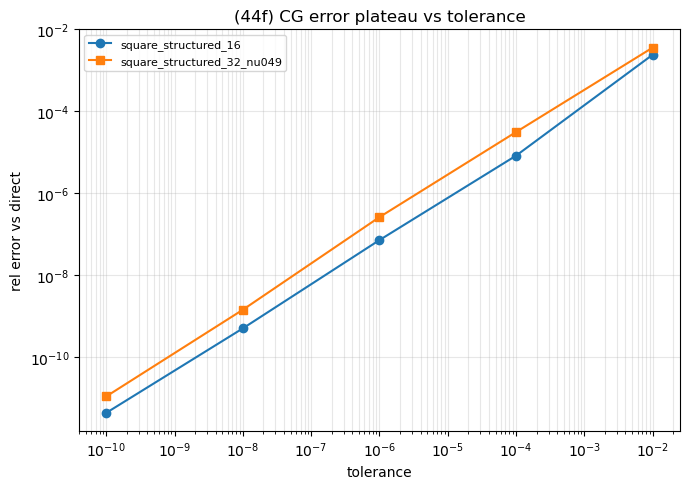

In [56]:
def cg_tol(K, f, tol, maxiter=None):
    K = K.tocsr(); n = K.shape[0]
    if maxiter is None: maxiter = 2 * n
    x = np.zeros(n); r = f - K @ x; p = r.copy(); rs = r @ r
    fn = np.linalg.norm(f) + 1e-30
    for it in range(1, maxiter + 1):
        Kp = K @ p; a = rs / (p @ Kp); x = x + a * p; r = r - a * Kp
        rs_new = r @ r
        if np.sqrt(rs_new) / fn < tol: return x, it
        p = r + (rs_new / rs) * p; rs = rs_new
    return x, maxiter

tols = [1e-2, 1e-4, 1e-6, 1e-8, 1e-10]
sweep_ids = [m for m in ['square_structured_16', 'square_structured_32_nu049'] if m in ZOO]
fig, ax = plt.subplots(figsize=(7, 5))
mk = {'square_structured_16': 'o', 'square_structured_32_nu049': 's'}
for mid in sweep_ids:
    s = ZOO[mid]; errs = []
    for t in tols:
        x, it = cg_tol(s['Kff'], s['Fff'], t)
        rho, e = solver_errors(s, x)
        errs.append(e)
        record_result('cg', s, solve_time_s=0.0, iterations=it, final_residual=rho,
                      rel_error=e, tol=t, converged=True)
    ax.loglog(tols, errs, mk.get(mid, 'o') + '-', label=mid)
ax.set(xlabel='tolerance', ylabel='rel error vs direct', title='(44f) CG error plateau vs tolerance')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## 44g — Setup vs solve split

Where the time goes for the methods with nonzero setup (Cholesky, LU, PCG-IC) on a few fine matrices.
The "preconditioners/factorizations are not free" point.

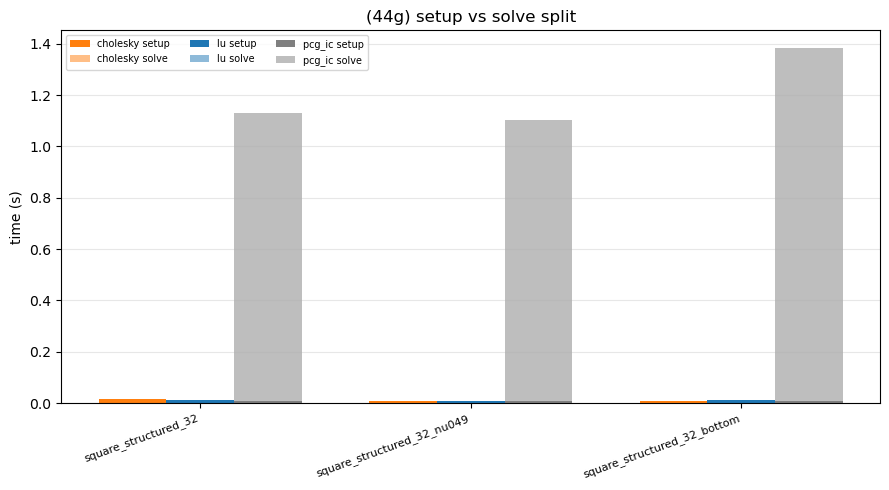

In [57]:
rep2 = [m for m in ['square_structured_32', 'square_structured_32_nu049', 'square_structured_32_bottom'] if m in set(RESULTS['matrix_id'])]
methods2 = ['cholesky', 'lu', 'pcg_ic']
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(rep2)); w = 0.25
for j, m in enumerate(methods2):
    setups, solves = [], []
    for mid in rep2:
        r = RESULTS[(RESULTS['method'] == m) & (RESULTS['matrix_id'] == mid)]
        setups.append(float(r['setup_time_s'].iloc[0]) if len(r) else np.nan)
        solves.append(float(r['solve_time_s'].iloc[0]) if len(r) else np.nan)
    setups = np.array(setups); solves = np.array(solves)
    pos = x + (j - 1) * w
    ax.bar(pos, setups, w, color=METHOD_COLOR[m], label=m + ' setup')
    ax.bar(pos, solves, w, bottom=setups, color=METHOD_COLOR[m], alpha=0.5, label=m + ' solve')
ax.set_xticks(x); ax.set_xticklabels(rep2, rotation=20, ha='right', fontsize=8)
ax.set_ylabel('time (s)'); ax.set_title('(44g) setup vs solve split')
ax.legend(fontsize=7, ncol=3); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

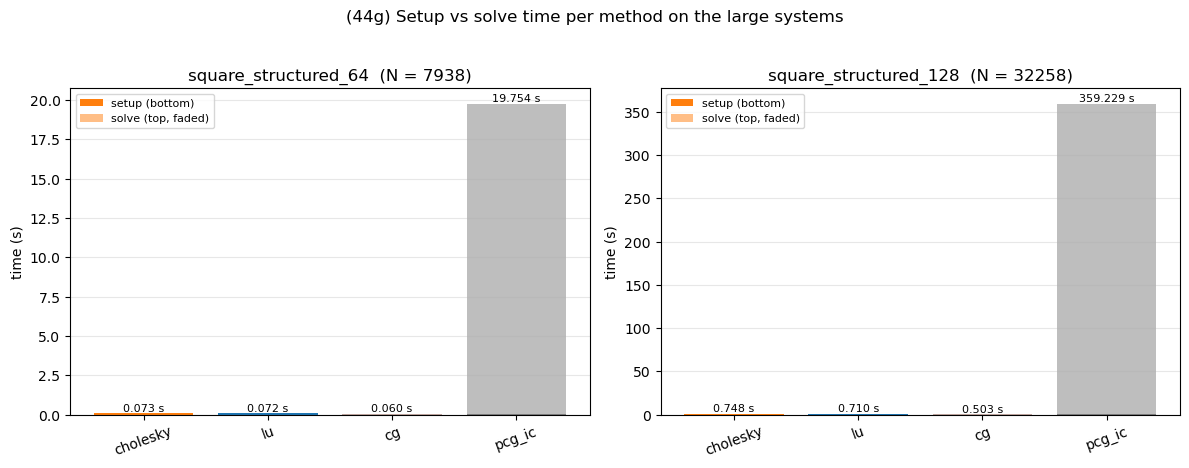

Large-matrix timings (s):
                      setup_time_s                          solve_time_s                            total_time_s                           
method                          cg cholesky      lu  pcg_ic           cg cholesky      lu    pcg_ic           cg cholesky      lu    pcg_ic
matrix_id                                                                                                                                  
square_structured_128          0.0   0.7355  0.6976  0.3663       0.5027   0.0126  0.0121  358.8627       0.5027   0.7481  0.7097  359.2290
square_structured_64           0.0   0.0711  0.0694  0.0500       0.0599   0.0022  0.0022   19.7043       0.0599   0.0733  0.0716   19.7543


In [58]:
# =====================================================================
# 44g. Large-matrix efficiency: setup vs solve per method (n=64, n=128)
# =====================================================================
large_ids = ['square_structured_64', 'square_structured_128']
methods_g = ['cholesky', 'lu', 'cg', 'pcg_ic']   # the four run on the large systems

fig, axs = plt.subplots(1, len(large_ids), figsize=(6 * len(large_ids), 4.5), sharey=False)
if len(large_ids) == 1:
    axs = [axs]

for ax, mid in zip(axs, large_ids):
    xs = np.arange(len(methods_g))
    setups, solves, totals = [], [], []
    for m in methods_g:
        r = RESULTS[(RESULTS['method'] == m) & (RESULTS['matrix_id'] == mid)]
        su = float(r['setup_time_s'].iloc[0]) if len(r) else np.nan
        so = float(r['solve_time_s'].iloc[0]) if len(r) else np.nan
        su = 0.0 if su != su else su          # treat NaN setup (CG) as 0
        so = 0.0 if so != so else so
        setups.append(su); solves.append(so); totals.append(su + so)

    b1 = ax.bar(xs, setups, color=[METHOD_COLOR[m] for m in methods_g], label='setup')
    b2 = ax.bar(xs, solves, bottom=setups, color=[METHOD_COLOR[m] for m in methods_g],
                alpha=0.5, label='solve')

    # annotate each bar with its total time
    for i, tot in enumerate(totals):
        ax.text(xs[i], tot, format(tot, '.3f') + ' s', ha='center', va='bottom', fontsize=8)

    N = ZOO[mid]['Kff'].shape[0]
    ax.set_xticks(xs); ax.set_xticklabels(methods_g, rotation=20)
    ax.set_ylabel('time (s)')
    ax.set_title(mid + '  (N = ' + str(N) + ')')
    ax.grid(True, axis='y', alpha=0.3)
    # solid = setup, faded = solve (same colour per method)
    ax.legend(['setup (bottom)', 'solve (top, faded)'], fontsize=8)

plt.suptitle('(44g) Setup vs solve time per method on the large systems', y=1.03)
plt.tight_layout(); plt.show()

# supporting table
print("Large-matrix timings (s):")
print(RESULTS[RESULTS['matrix_id'].isin(large_ids)]
      .pivot_table(index='matrix_id', columns='method',
                   values=['setup_time_s', 'solve_time_s', 'total_time_s'], aggfunc='first')
      .round(4).to_string())


In [ ]:
# --- Export RESULTS for the report ---
RESULTS.to_csv('RESULTS.csv', index=False)
print("wrote RESULTS.csv :", RESULTS.shape[0], "rows x", RESULTS.shape[1], "cols")
print("methods:", sorted(RESULTS['method'].unique()))
print("matrices:", RESULTS['matrix_id'].nunique())

# download if using Colab
try:
    from google.colab import files
    files.download('RESULTS.csv')
except Exception as e:
    print("not in Colab (or download unavailable):", e)
    print("file is saved in the working directory as RESULTS.csv")

wrote RESULTS.csv : 370 rows x 21 cols
methods: ['cg', 'cholesky', 'gs', 'jacobi', 'lu', 'minres', 'pcg_ic', 'qr']
matrices: 46
not in Colab (or download unavailable): No module named 'google.colab'
file is saved in the working directory as RESULTS.csv
